# Exploratory Analysis of Japanese Stocks
## Exploring the relationship between stock movements, USD/Yen movements, and export shares


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from functools import reduce

#First Initializing all the Stock data
yen_usd = pd.read_csv("USD_Yen.csv")
idemitsu = pd.read_csv("Idemitsu Kosan (Gas).csv")
mitsubishi = pd.read_csv("Mitsubishi Chemical (Chemical).csv")
oji = pd.read_csv("Oji Holding (Paper, Wood, Pulp).csv")
teijin = pd.read_csv("Teijin (Textiles).csv")
ajinomoto = pd.read_csv("Ajinomoto (Food).csv")
kajima = pd.read_csv("Kajima Corp (Construction).csv")
okuma = pd.read_csv("Okuma Corp (Production Machinery).csv")
kewpie = pd.read_csv("Kewpie (Food).csv")
toyota = pd.read_csv("Toyota (Transportation).csv")
toray = pd.read_csv("Toray (Textiles).csv")
meiji = pd.read_csv("Meiji Holdings (Food).csv")
nippon_paper = pd.read_csv("Nippon Paper (paper, pulp, wood).csv")
shin_etsu = pd.read_csv("Shin-etsu (Chemical).csv")
eneos = pd.read_csv("Eneos (Gas).csv")
nikkei = pd.read_csv("Nikkei 255.csv")
honda = pd.read_csv("Honda (Transportation).csv")
tokyo_electron = pd.read_csv("Tokyo Electronic (Production Machinery).csv")
obayashi = pd.read_csv("Obayashi Corp (Construction).csv")

stock_list = [idemitsu,
              mitsubishi,
              oji,
              teijin,
              ajinomoto,
              kajima,
              okuma,
              kewpie,
              toyota,
              toray,
              meiji,
              nippon_paper,
              shin_etsu,
              eneos,
              yen_usd,
              nikkei,
              honda,
              tokyo_electron,
              obayashi
             ]

stock_names = ["idemitsu",
              "mitsubishi",
              "oji",
              "teijin",
              "ajinomoto",
              "kajima",
              "okuma",
              "kewpie",
              "toyota",
              "toray",
              "meiji",
              "nippon_paper",
              "shin_etsu",
              "eneos",
              "yen_usd",
              "nikkei",
               "honda",
               "tokyo_electron",
               "obayashi"
             ]
#Cleaning Stock Column Names
for stock in stock_list:
    stock.columns = stock.columns.str.strip()

### Normalizing the stock information and creating additional columns for daily and total change

In [2]:
#Adjusting the Date for the stocks and sorting by date
for stock in stock_list:
    stock["Date"] = pd.to_datetime(stock["Date"], format="%m/%d/%y")
    stock.sort_values("Date", inplace=True)
    stock.reset_index(drop=True, inplace=True)

#Creating the percent daily change and total change    
    stock["Daily_Change"] = stock["Close"].pct_change() * 100
    stock["Total_Change"] = ((stock["Close"] / stock["Close"].iloc[0] - 1) * 100).round(2)
                                                                                        
#Changing all column names to be more descriptive
for i, stock in enumerate(stock_list):
    stock = stock.rename(columns={'Daily_Change': f'{stock_names[i]}_Daily_Change', 'Total_Change': f'{stock_names[i]}_Total_Change'},
                        inplace = True)

### Confirming that Wsj data is pre-adjusted for Stock Consolidation / Splits
Stocks are confirmed pre-adjusted

In [3]:
#Checking if data is corrected for stock splits
# Dictionary with the dates of recorded split or consolidation
stock_splits = {
    "Idemitsu": (idemitsu, ["2023-12-28"]),
    "Teijin": (teijin, ["2016-09-28"]),
    "Kajima": (kajima, ["2018-09-26"]),
    "Okuma": (okuma, ["2017-09-27", "2024-09-27"]),
    "Meiji": (meiji, ["2015-09-28", "2023-03-30"]),
    "Shin-Etsu": (shin_etsu, ["2023-03-30"]),
    "toyota": (toyota, ["2021-09-24", "2021-10-01"]),
    "Honda": (honda, ["2023-09-28"]),
    "Tokyo Electronic": (tokyo_electron, ["2023-03-30"])
}

#Unpacking the touple and iterating the names of stock
for name, (df, dates) in stock_splits.items():
    
    print(f"\n{name}")

#Sorting through the dates  
    for date in dates:
        split_date = pd.Timestamp(date)

        start = split_date - pd.Timedelta(days=5)
        end = split_date + pd.Timedelta(days=5)

        print(f"\nChecking {date}:")

#displaying the window of stock splits to check if the data has already been adjusted
#big jumps or fall indicate data is not yet adjusted
        display(
            df.loc[
                df["Date"].between(start, end),
                ["Date", "Close"]
            ]
        )


Idemitsu

Checking 2023-12-28:


,Date,Close
2380,2023-12-25,767
2381,2023-12-26,771
2382,2023-12-27,783
2383,2023-12-28,786
2384,2023-12-29,768



Teijin

Checking 2016-09-28:


,Date,Close
608,2016-09-23,1990
609,2016-09-26,2005
610,2016-09-27,2015
611,2016-09-28,1946
612,2016-09-29,1988
613,2016-09-30,1948
614,2016-10-03,1957



Kajima

Checking 2018-09-26:


,Date,Close
1100,2018-09-21,1664
1101,2018-09-25,1682
1102,2018-09-26,1656
1103,2018-09-27,1631
1104,2018-09-28,1651
1105,2018-10-01,1649



Okuma

Checking 2017-09-27:


,Date,Close
854,2017-09-22,2890
855,2017-09-25,2945
856,2017-09-26,2963
857,2017-09-27,2975
858,2017-09-28,2980
859,2017-09-29,3080
860,2017-10-02,3080



Checking 2024-09-27:


,Date,Close
2562,2024-09-24,2950
2563,2024-09-25,3024
2564,2024-09-26,3074
2565,2024-09-27,3178
2566,2024-09-30,3063
2567,2024-10-01,3133
2568,2024-10-02,3115



Meiji

Checking 2015-09-28:


,Date,Close
364,2015-09-24,4298
365,2015-09-25,4508
366,2015-09-28,4425
367,2015-09-29,4180
368,2015-09-30,4370
369,2015-10-01,4315
370,2015-10-02,4495



Checking 2023-03-30:


,Date,Close
2194,2023-03-27,3205
2195,2023-03-28,3215
2196,2023-03-29,3235
2197,2023-03-30,3150
2198,2023-03-31,3155
2199,2023-04-03,3180
2200,2023-04-04,3200



Shin-Etsu

Checking 2023-03-30:


,Date,Close
2194,2023-03-27,4192
2195,2023-03-28,4142
2196,2023-03-29,4206
2197,2023-03-30,4161
2198,2023-03-31,4275
2199,2023-04-03,4182
2200,2023-04-04,4155



toyota

Checking 2021-09-24:


,Date,Close
1825,2021-09-21,1986
1826,2021-09-22,1964
1827,2021-09-24,2020
1828,2021-09-27,2066
1829,2021-09-28,2077
1830,2021-09-29,2073



Checking 2021-10-01:


,Date,Close
1828,2021-09-27,2066
1829,2021-09-28,2077
1830,2021-09-29,2073
1831,2021-09-30,2000
1832,2021-10-01,1967
1833,2021-10-04,1932
1834,2021-10-05,1902
1835,2021-10-06,1840



Honda

Checking 2023-09-28:


,Date,Close
2318,2023-09-25,1751
2319,2023-09-26,1747
2320,2023-09-27,1752
2321,2023-09-28,1731
2322,2023-09-29,1682
2323,2023-10-02,1689
2324,2023-10-03,1645



Tokyo Electronic

Checking 2023-03-30:


,Date,Close
2194,2023-03-27,3250
2195,2023-03-28,3239
2196,2023-03-29,3221
2197,2023-03-30,3206
2198,2023-03-31,3208
2199,2023-04-03,3142
2200,2023-04-04,3161


### Combining Stock Data Into a New Data Frame

In [4]:
#Creating a dictionary with stock name as key and df as value
stocks = dict(zip(stock_names, stock_list))

#Creating a list of dfs with close prices and daily changes
stock_dfs = []

for name, df in stocks.items():
    date_close = df[["Date", "Close", f"{name}_Daily_Change"]].copy()

    date_close.rename(
        columns = {
            "Close": name,
            f"{name}_Daily_Change": f"{name}_day_change"
        },
        inplace = True
    )

    stock_dfs.append(date_close)

#Using reduce() to combine all the dfs on common dates
stock_prices = reduce(
    lambda left, right: pd.merge(left, right, on="Date", how="inner"),
    stock_dfs
)

#Creating the total percent change columns
for name in stocks:

    stock_prices[f"{name}_total_change"] = (
        (stock_prices[name] / stock_prices[name].iloc[0] - 1) * 100
    ).round(2)


stock_prices.head()

,Date,idemitsu,idemitsu_day_change,mitsubishi,mitsubishi_day_change,oji,oji_day_change,teijin,teijin_day_change,ajinomoto,...,toray_total_change,meiji_total_change,nippon_paper_total_change,shin_etsu_total_change,eneos_total_change,yen_usd_total_change,nikkei_total_change,honda_total_change,tokyo_electron_total_change,obayashi_total_change
0,2014-04-01,416,NaN,425,NaN,448,NaN,1280,NaN,754,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,2014-04-02,422,1.442308,428,0.705882,454,1.339286,1290,0.781250,747,...,0.44,-1.14,3.76,0.25,1.42,0.22,1.04,1.24,4.03,1.00
2,2014-04-03,424,0.473934,427,-0.233645,463,1.982379,1295,0.387597,746,...,1.46,-2.09,3.61,0.00,1.42,0.26,1.89,2.24,5.21,1.00
3,2014-04-04,425,0.235849,433,1.405152,458,-1.079914,1265,-2.316602,745,...,1.17,-2.72,4.54,0.42,2.03,-0.36,1.84,1.58,4.74,2.33
4,2014-04-07,425,0.000000,428,-1.154734,454,-0.873362,1250,-1.185771,742,...,0.29,-3.68,5.15,-1.19,1.83,-0.54,0.11,-1.33,1.90,4.15


## Summary Statistics for Each Stock and Graphs against USD/Yen

In [5]:
#Creating the names of the columns
daily_cols = [name + "_day_change" for name in stocks]

#Creating the summaries and transposing adjusting so stock names are on left with .T
summary = stock_prices[daily_cols].describe().T
summary["total_return"] = [stock_prices[name + "_total_change"].iloc[-1] for name in stocks]
print(summary[["mean", "std", "min", "max", "total_return"]].round(4))

                             mean     std      min      max  total_return
idemitsu_day_change        0.0555  2.0506 -11.1963  18.3261        153.12
mitsubishi_day_change      0.0376  1.8489 -13.5889  12.3389         73.41
oji_day_change             0.0280  1.7581  -8.7683  13.6471         39.96
teijin_day_change          0.0145  1.6480 -11.7956  11.6695          2.42
ajinomoto_day_change       0.0647  1.6650 -10.1973  11.3540        292.44
kajima_day_change          0.0678  1.7905 -13.3515  15.0494        302.11
okuma_day_change           0.0427  2.2493 -15.1791  14.8171         59.87
kewpie_day_change          0.0393  1.5915  -9.4358  15.6631        105.06
toyota_day_change          0.0440  1.6641 -13.6557  12.8136        124.94
toray_day_change           0.0300  1.7509 -13.2514  12.4113         48.10
meiji_day_change           0.0385  1.5263 -10.3926  16.9828        105.96
nippon_paper_day_change   -0.0097  1.7090 -15.7113  14.9955        -48.04
shin_etsu_day_change       0.0654  1.8

### Summary Stats Observations

Looking only at the summary statistics the stocks that are closest to the same total return as USD/Yen movements are Toray, Oji, and Okuma.

These are textile, wood/paper/pulp, and production machinery sector businesses.

We can also observe that the standard eviation for Yen_USD is .568, and is the only standard deviation that is below 1. When we look at the means between all categories, the most similar to yen/usd is teijin and honda with .0145 and .0215 compared to .0160

## Creating Line Plots of Daily Changes, Adjusted Daily Changes, and Total Changes
#### Line plots of Day Change compared to yen/usd

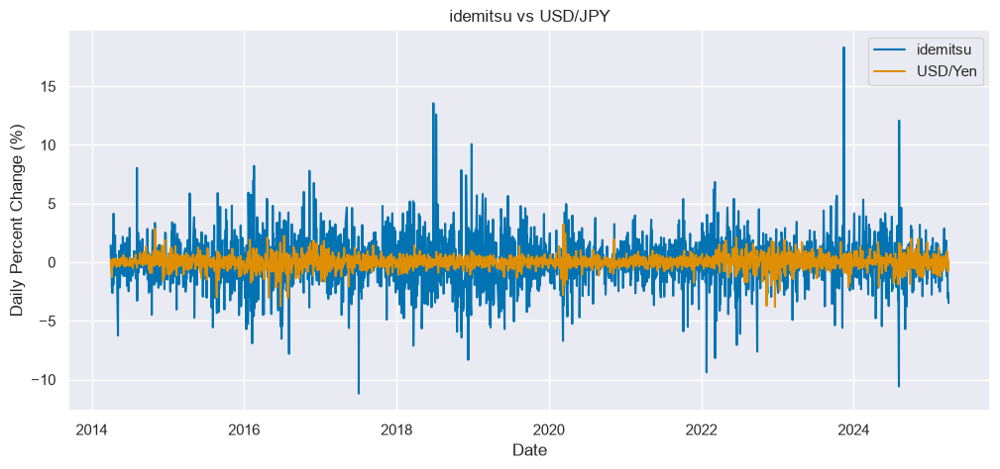

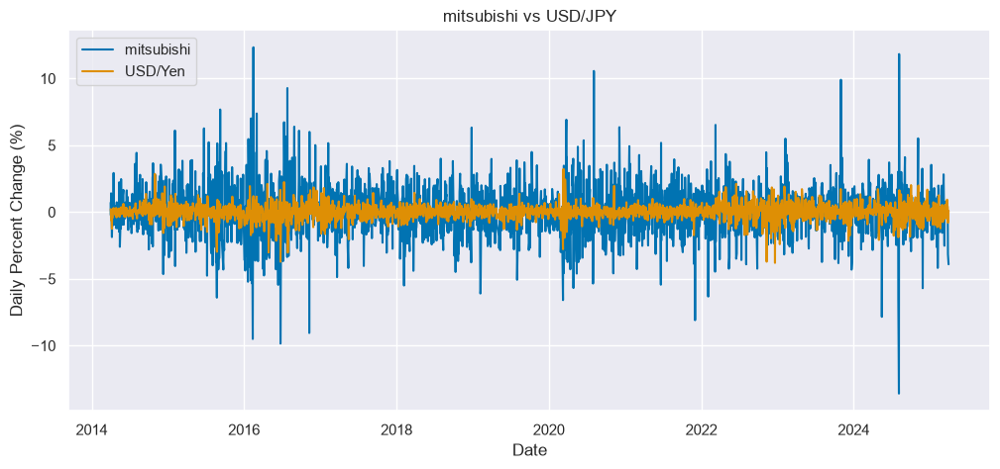

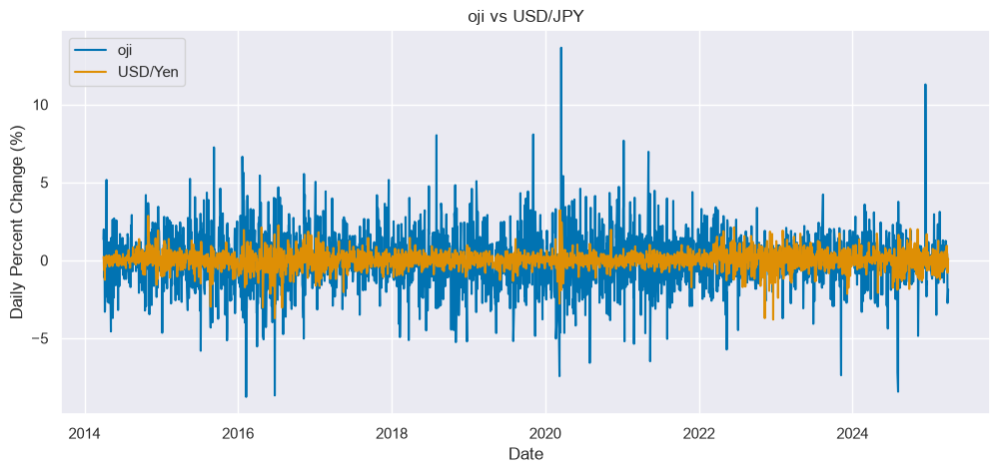

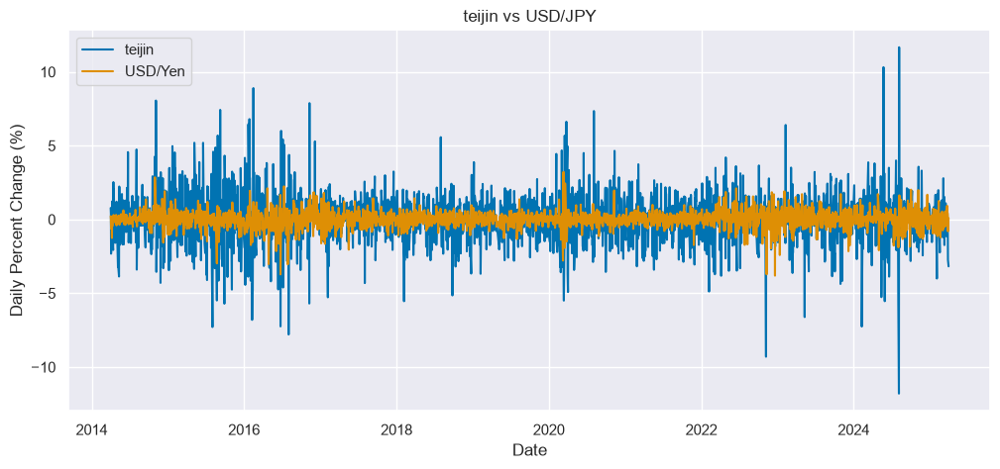

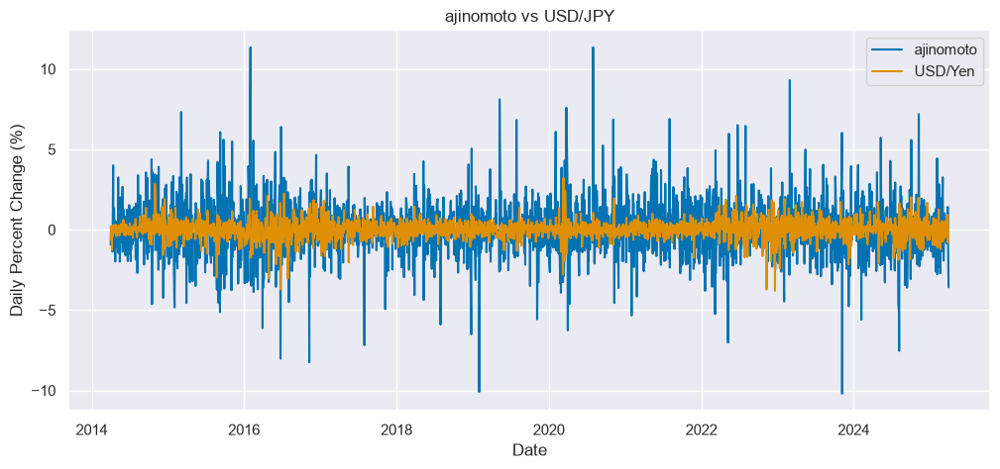

...

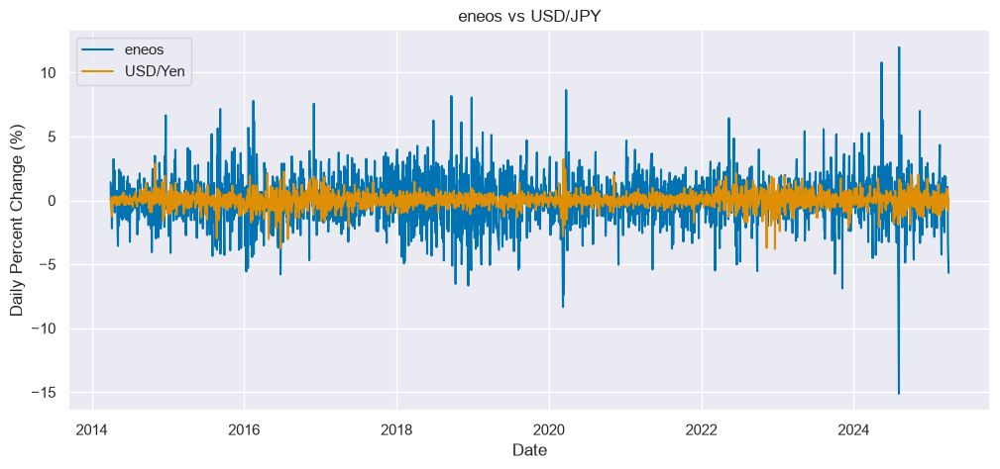

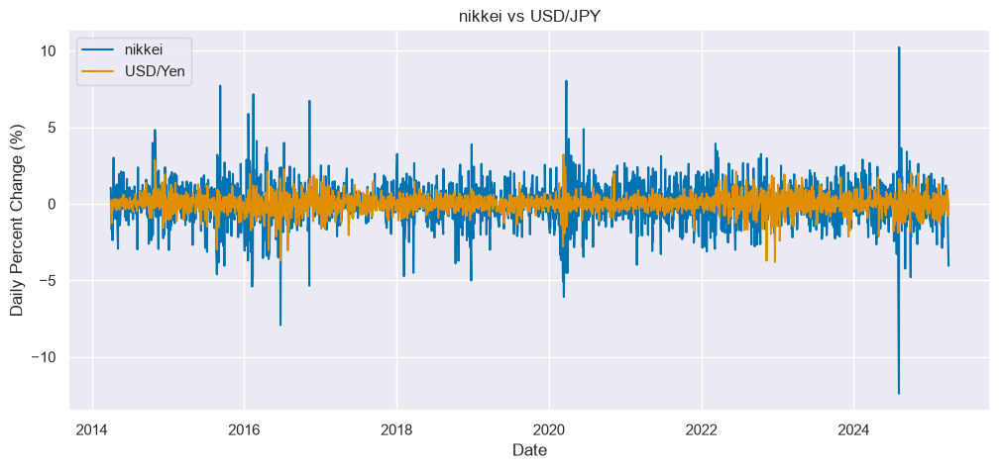

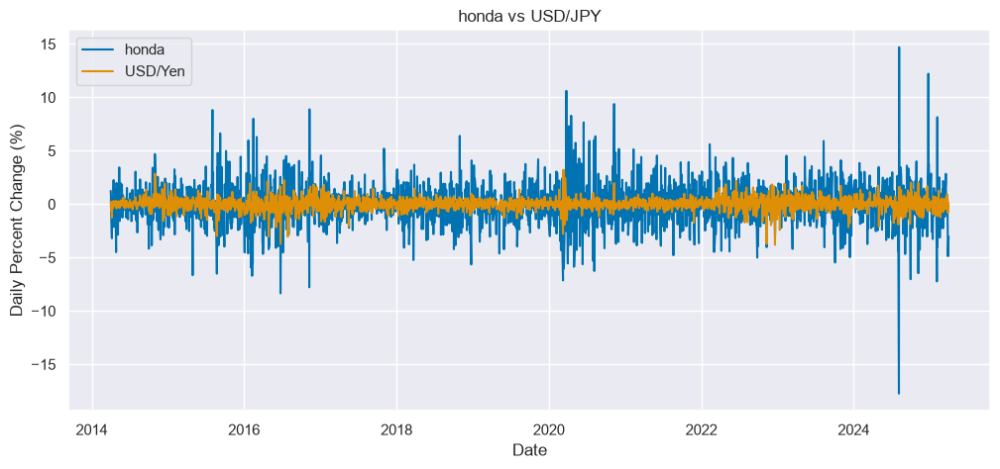

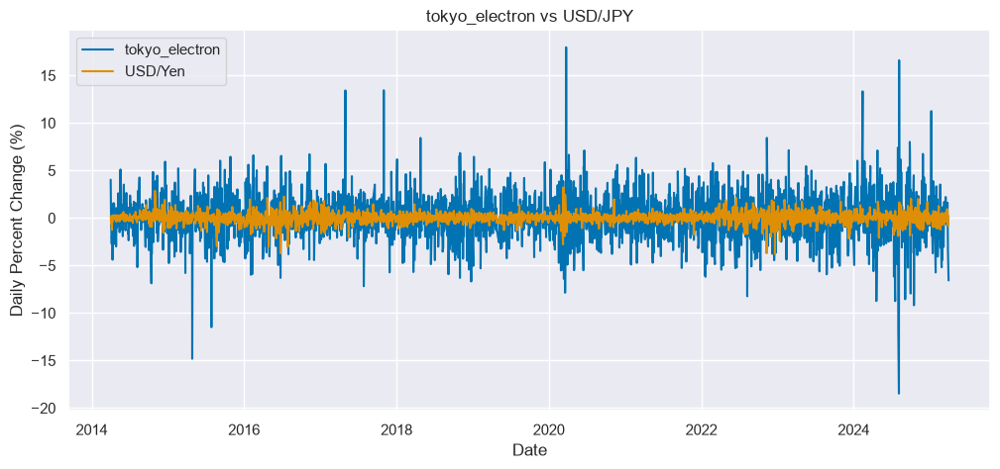

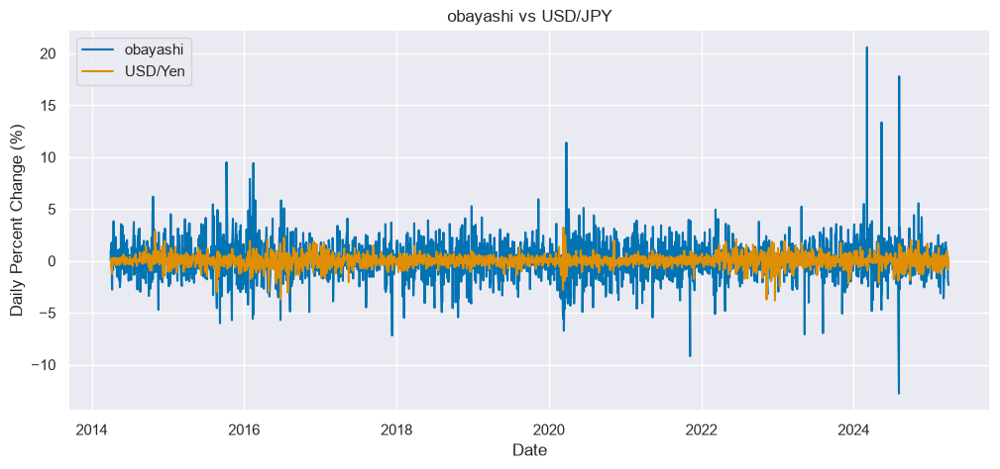

In [6]:
sns.set_theme(palette = "colorblind")
for name in stocks:
    if name in "yen_usd":
        continue
        
    plt.figure(figsize = (12,5))

    sns.lineplot(
        data = stock_prices, 
        x = "Date", 
        y = f"{name}_day_change",
        label = name
    )

    sns.lineplot(
        data = stock_prices,
        x = "Date",
        y = "yen_usd_day_change",
        label = "USD/Yen"
    )

    plt.title(f"{name} vs USD/JPY")
    plt.ylabel("Daily Percent Change (%)")
    plt.xlabel("Date")
    plt.legend()
    plt.show()

### The above plots were pretty noisy, below are the graphs looking at monthly change

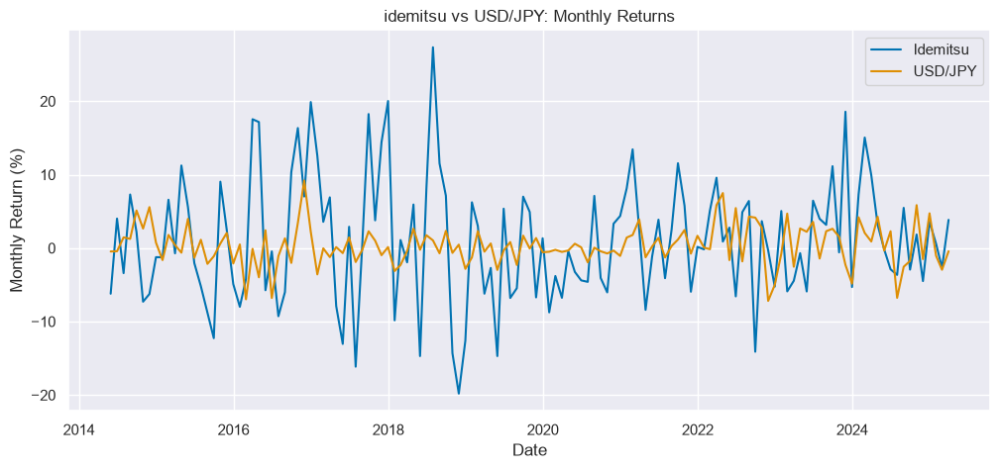

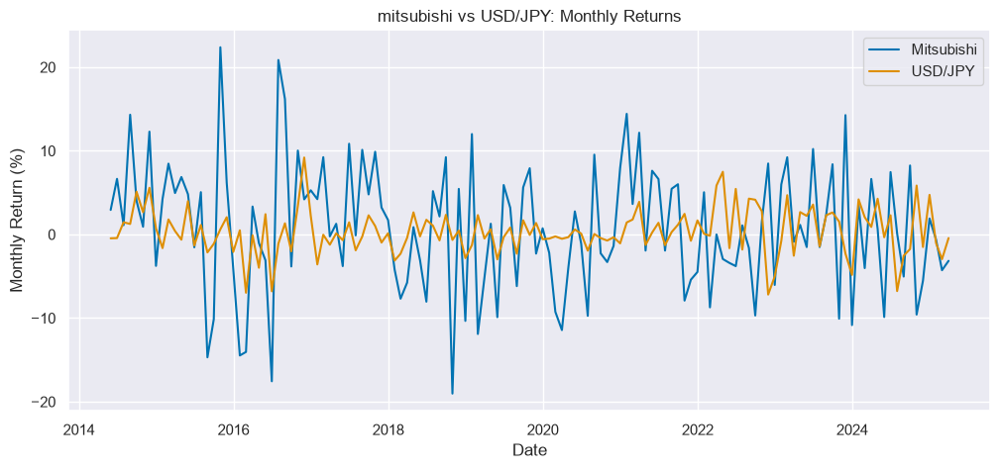

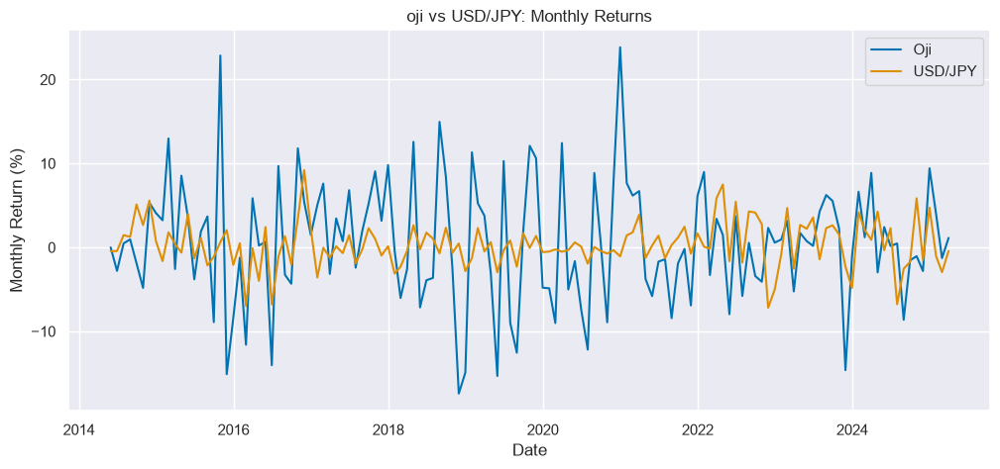

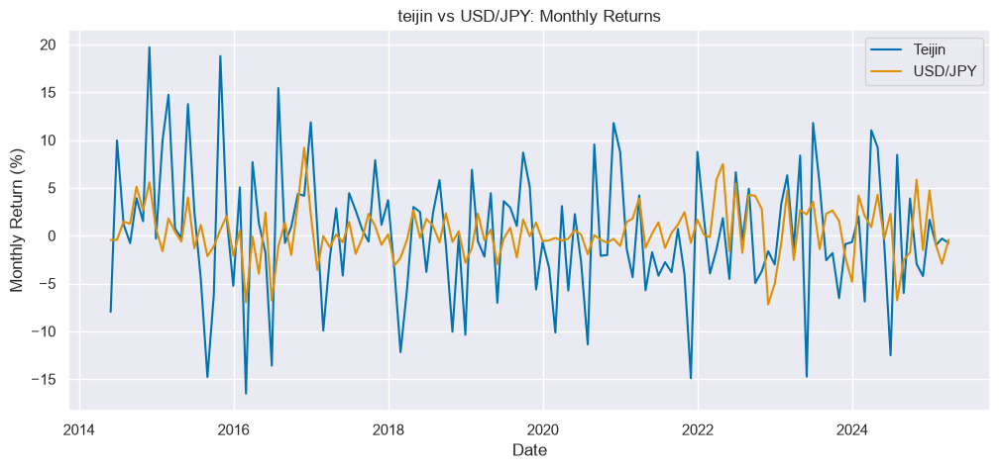

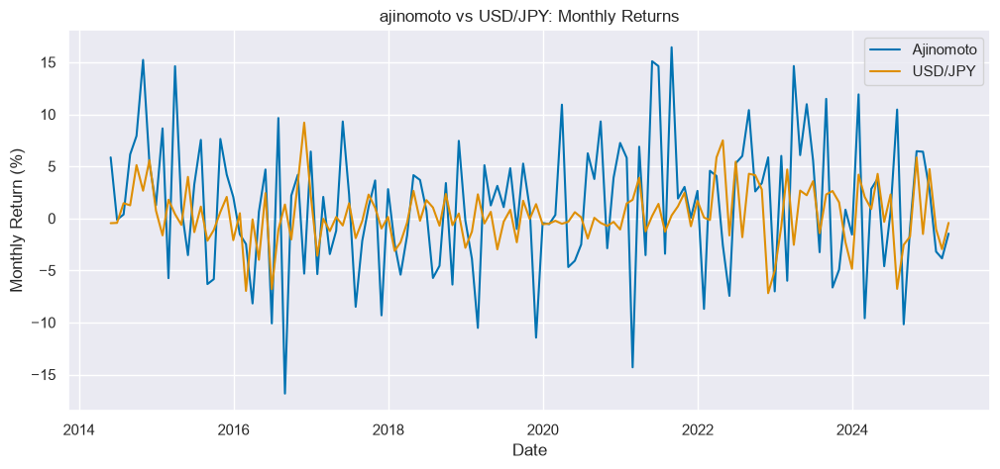

...

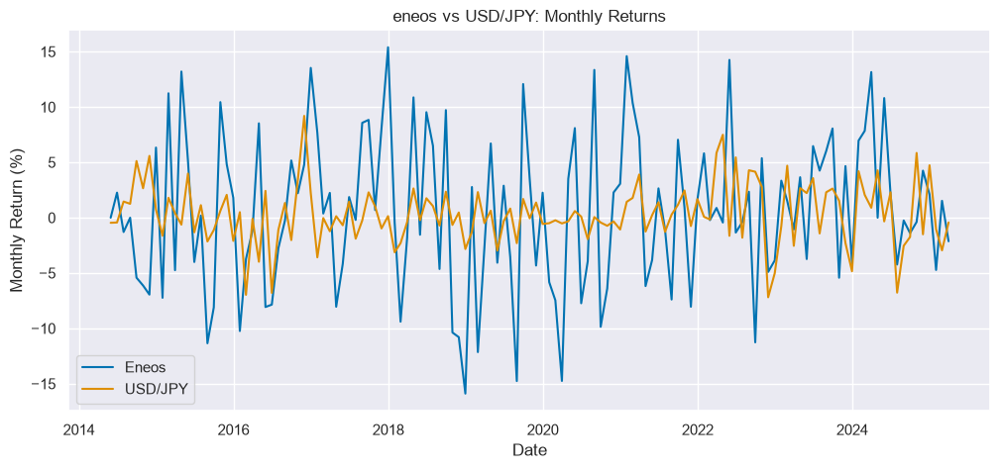

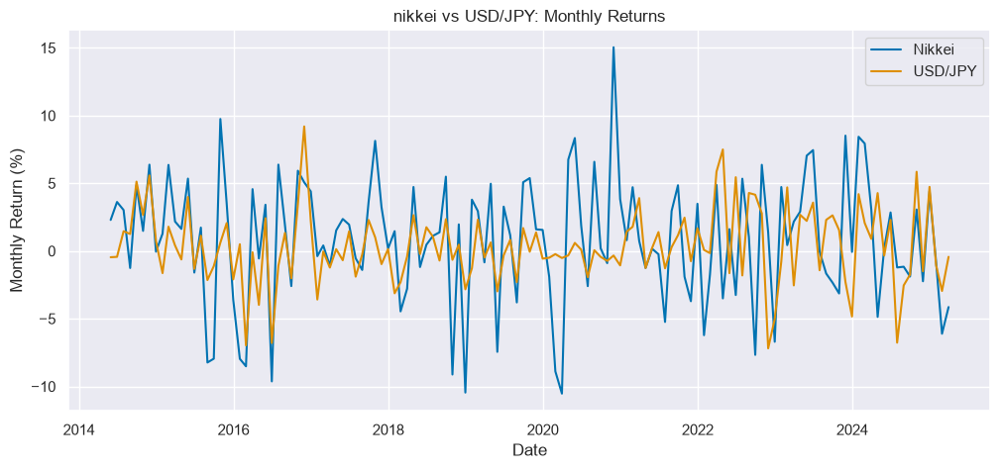

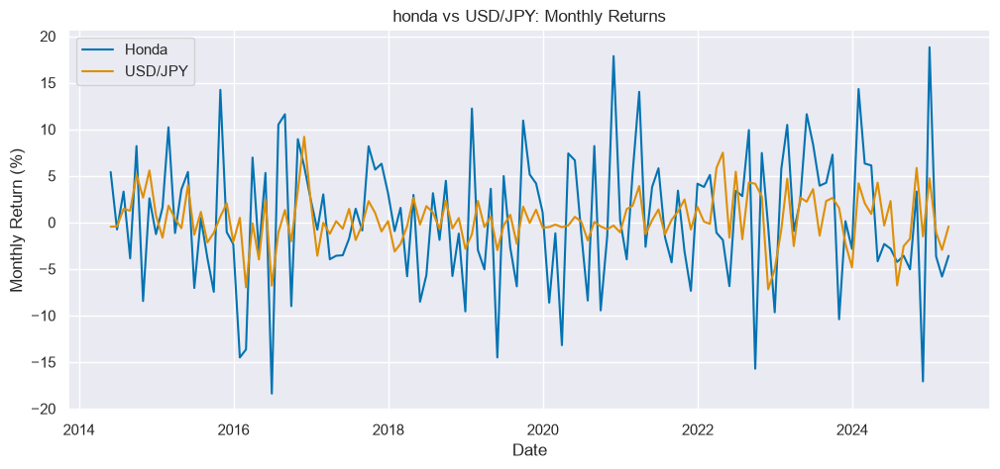

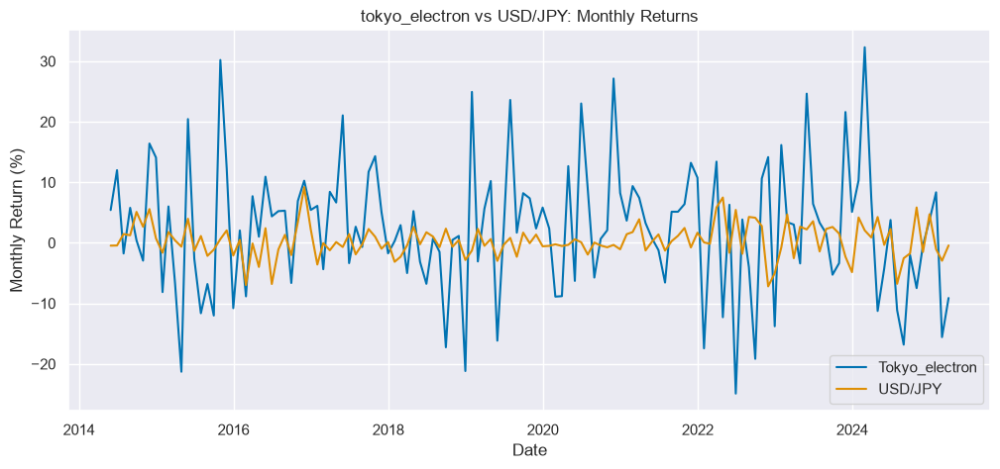

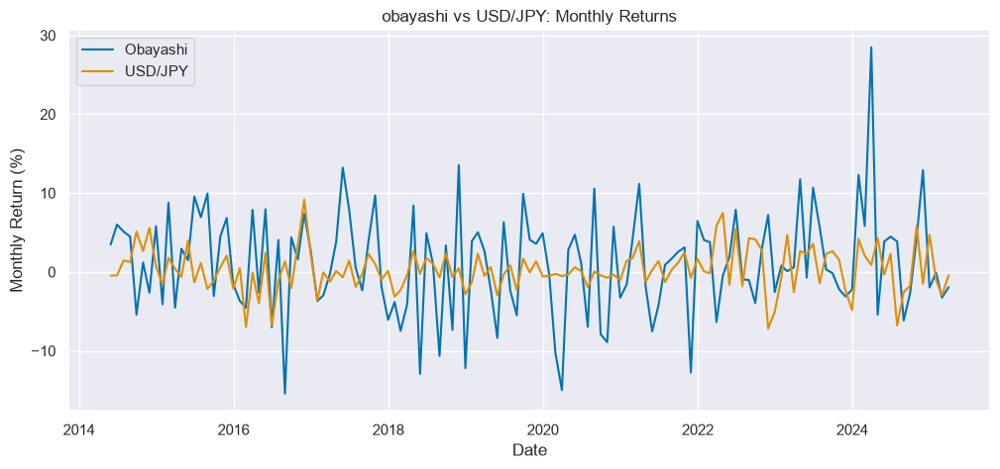

In [7]:
# Select original closing price columns / ME organizes based on months, like groupby but for dates
# .last() picks the last data point of the month
monthly_prices = (
    stock_prices
    .set_index("Date")[stock_names]
    .resample("ME")
    .last()
)

# Calculate monthly returns
monthly_returns = monthly_prices.pct_change(fill_method=None) * 100

monthly_returns = monthly_returns.reset_index()

#Looping over stock names to create visualizations for every stock
for name in stocks:
    
    if name in "yen_usd":
        continue
        
    plt.figure(figsize=(12, 5))

    sns.lineplot(
        data = monthly_returns,
        x = "Date",
        y = name,
        label = name.capitalize()
)

    sns.lineplot(
        data = monthly_returns,
        x = "Date",
        y = "yen_usd",
        label = "USD/JPY"
)

    plt.title(f"{name} vs USD/JPY: Monthly Returns")
    plt.ylabel("Monthly Return (%)")
    plt.show()

### Looking at Cumulative Change Over Date vs Yen/USD

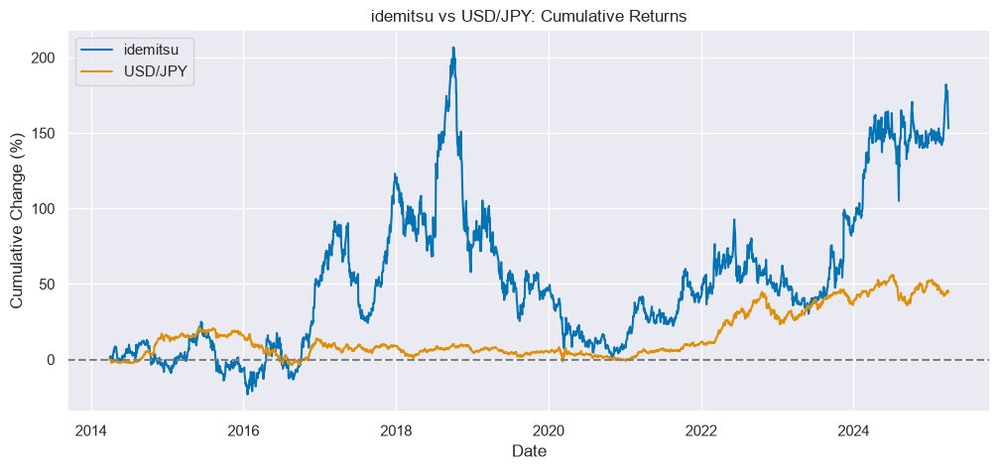

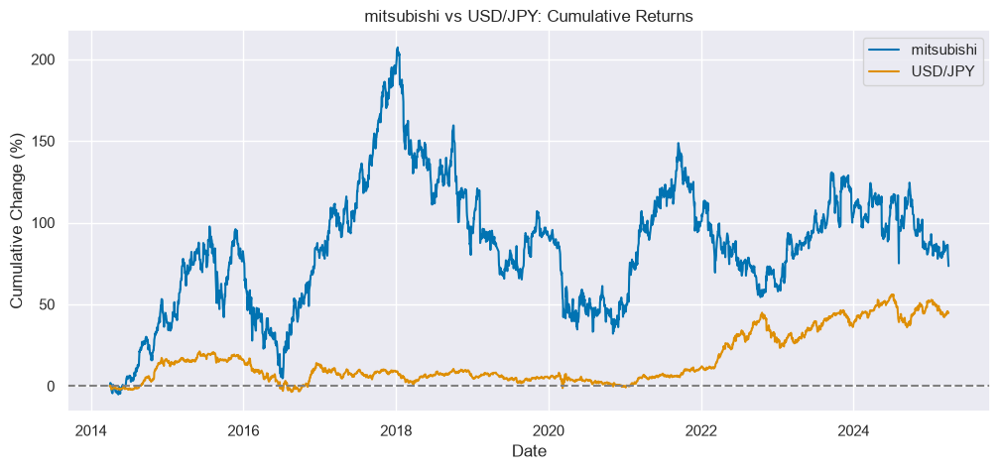

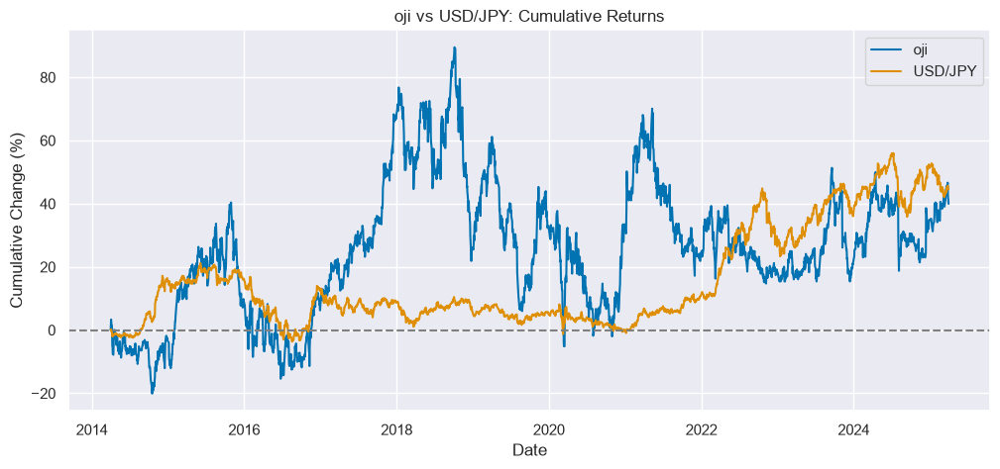

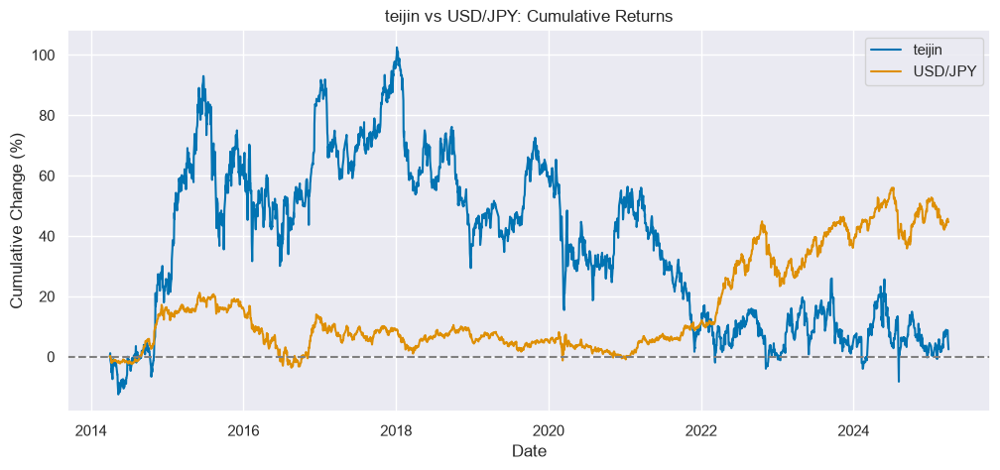

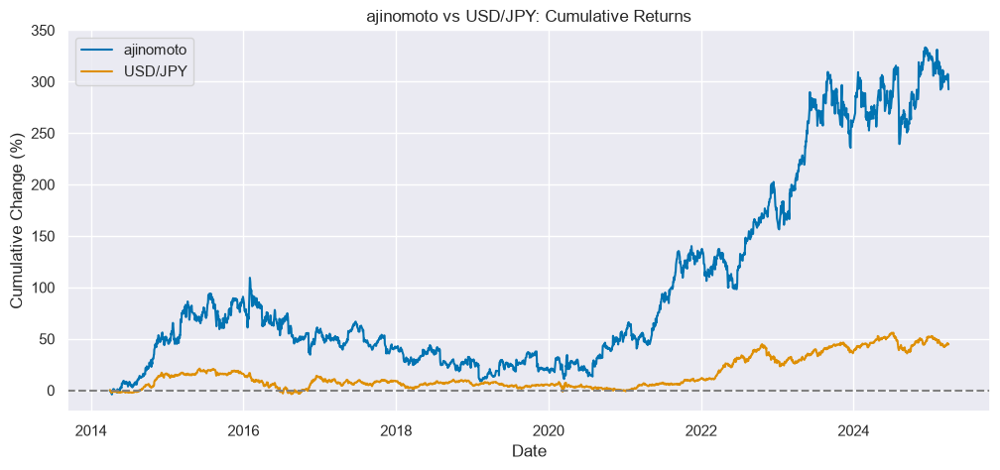

...

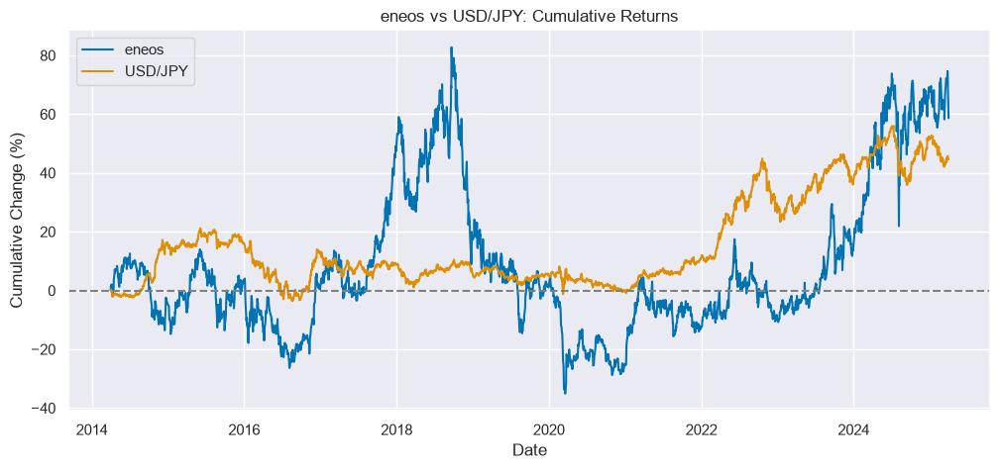

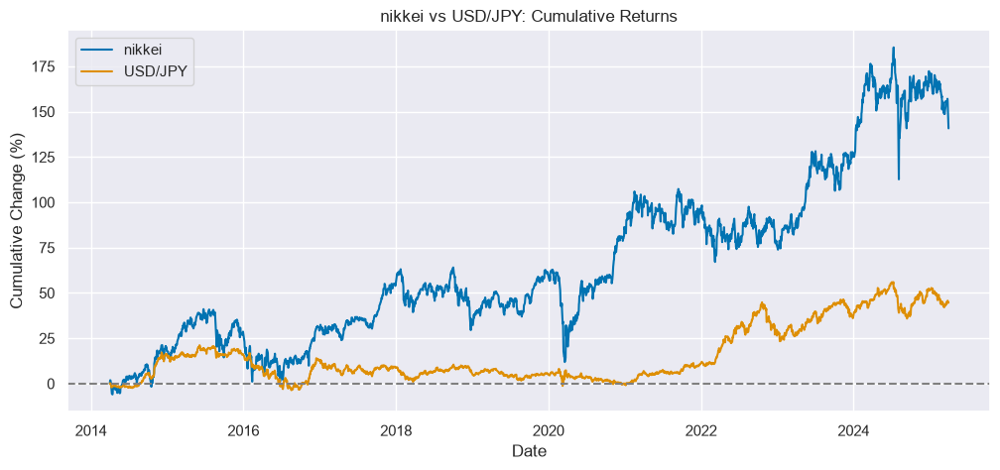

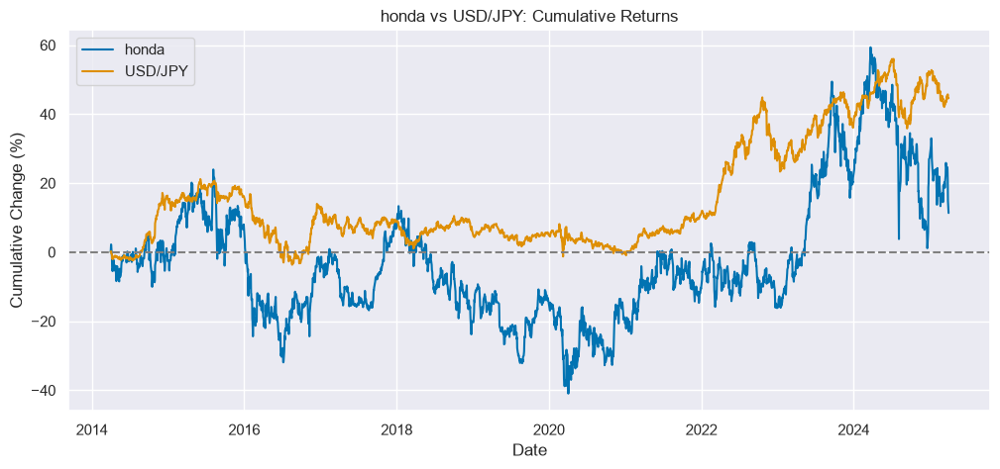

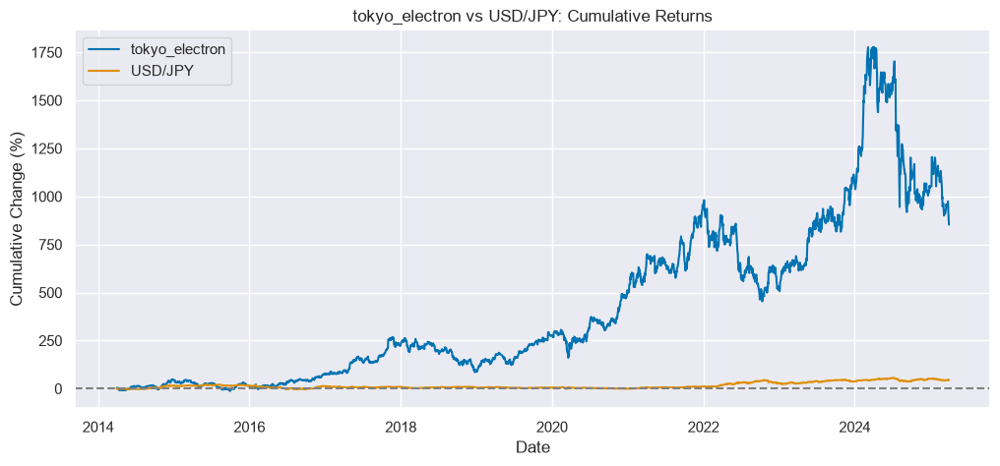

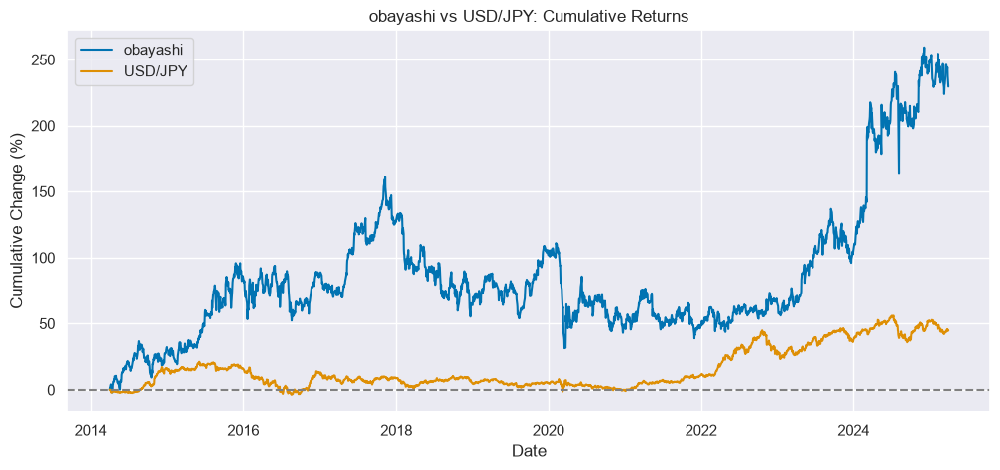

In [8]:
for name in stocks:

    if name in "yen_usd":
        continue

    plt.figure(figsize=(12, 5))

    sns.lineplot(
        data=stock_prices,
        x="Date",
        y=f"{name}_total_change",
        label=name
    )

    sns.lineplot(
        data=stock_prices,
        x="Date",
        y="yen_usd_total_change",
        label="USD/JPY"
    )

    plt.title(f"{name} vs USD/JPY: Cumulative Returns")
    plt.xlabel("Date")
    plt.ylabel("Cumulative Change (%)")
    plt.axhline(0, color="gray", linestyle="--")
    plt.legend()
    plt.show()

### Graph Takeaways
#### Looking at all three graphs so far, it appears that some of the stocks follow the Yen/USD trends or follow the inverse of their trends

For example, Oji (Paper) month returns seem to be following closely the Yen/USD movements at different magnitudes. Same with Mitsubishi (Chemical), and Teijin (Textiles). The Nikkei index also appears to have movements resembling many of the fluxuations of the USD/Yen exchange rate. Looking at the food industries (Kewpie, Meiji, Ajinomoto) many of their movements appear to be taking the inverse of the movements of Yen/Usd. This may be occuring because many of their inputs are sourced from foreign imports then mostly sold within Japan.

If we look at the cumuluative change graphs, ignoring drops during COVID 19, we again see some graphs following the trends or the inverse. For example Teijin stocks crashed in 2022 when USD prices surged, as well as Oji and Meiji. Remarkably Kewpie follows the upward trends with USD in 2022 and movements look quite similar past that point.


###### (Important note! ajinomoto is primarily a food company, but also produces semi conductor material. Potentially a reason why their stock change blows up so much around 2022)

### Correlation Analysis
#### Stocks daily return % compared to USD/Yen Daily Change %

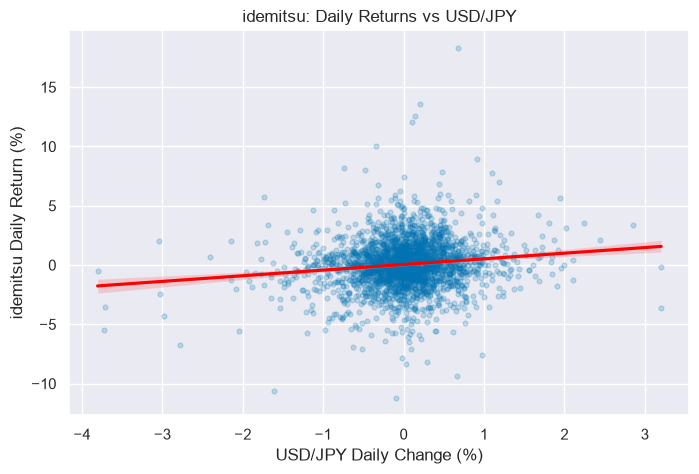

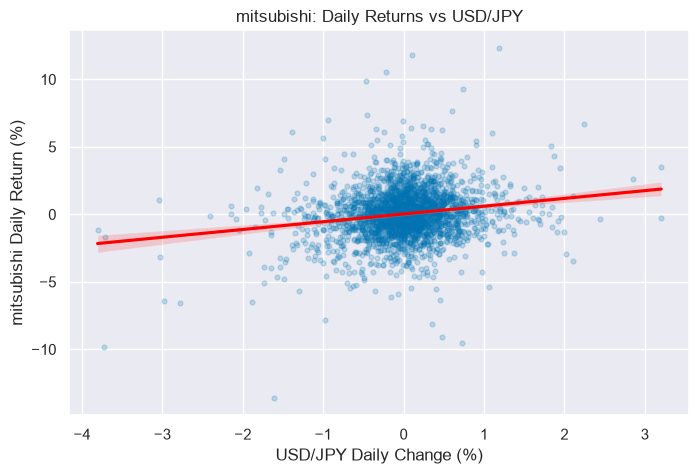

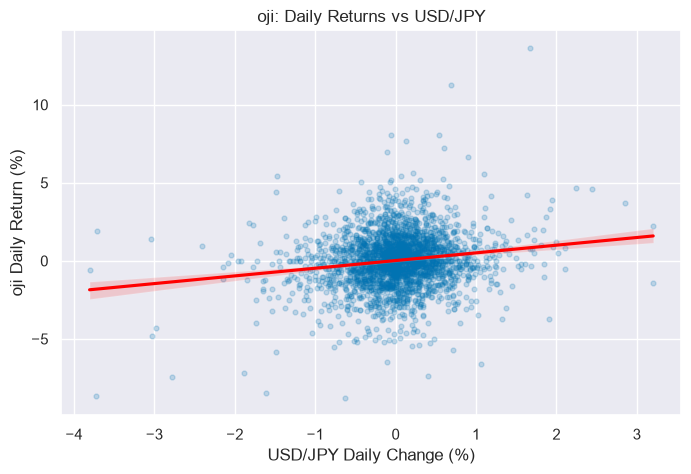

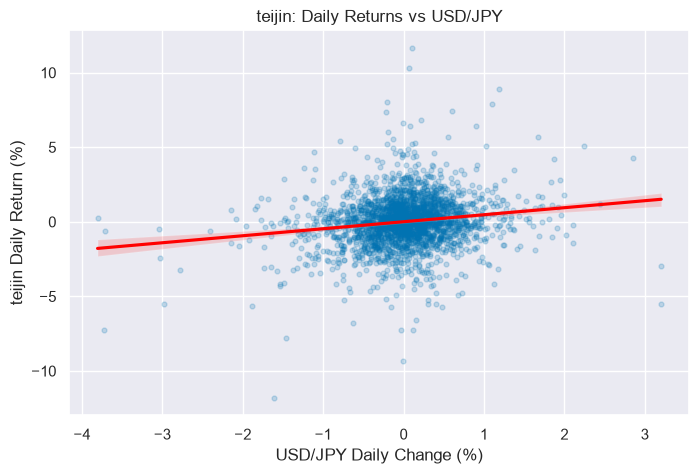

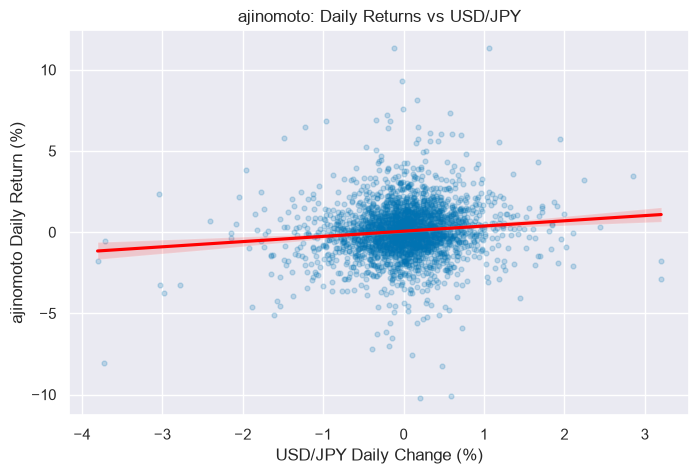

...

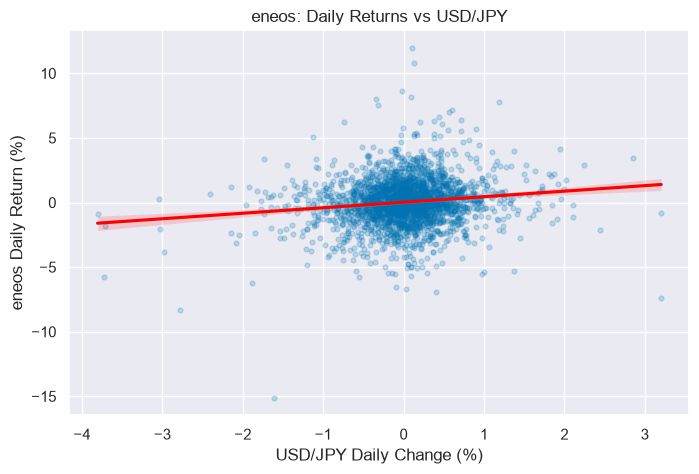

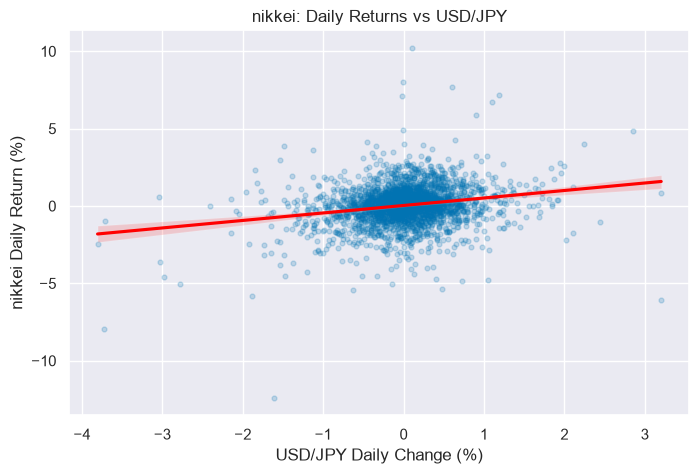

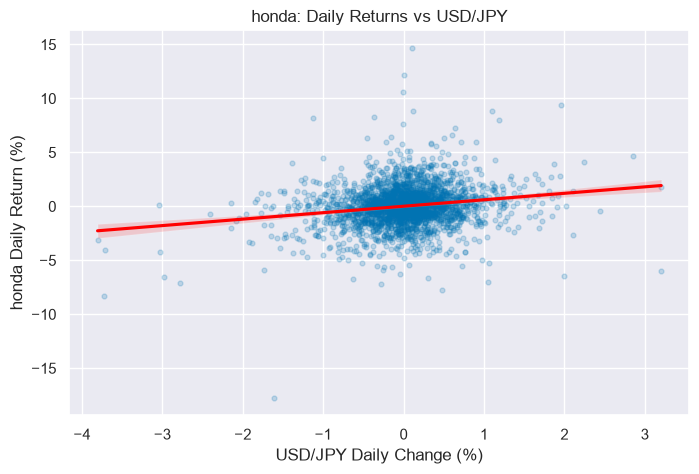

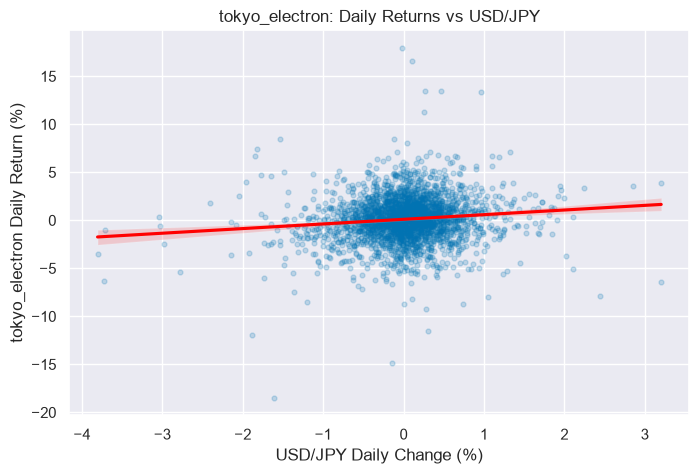

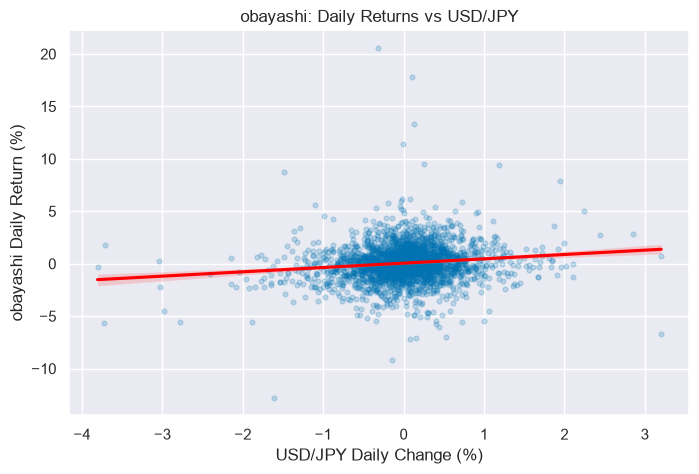

In [9]:
for name in stocks:

    if name == "yen_usd":
        continue

    plt.figure(figsize=(8, 5))

    sns.regplot(
        data = stock_prices,
        x = "yen_usd_day_change",
        y = f"{name}_day_change",
        scatter_kws = {"alpha": 0.2, "s": 12},
        line_kws = {"color": "red"}
    )

    plt.title(f"{name}: Daily Returns vs USD/JPY")
    plt.xlabel("USD/JPY Daily Change (%)")
    plt.ylabel(f"{name} Daily Return (%)")
    plt.show()

### These correlations are rather compressed, but the data shows that when looking at a daily window most of the stocks have 0 to weak correlations to USD/Yen movements. Below we will be looking at the correlations with rolling windows and monthly returns

### Correlations looking at Monthly Changes

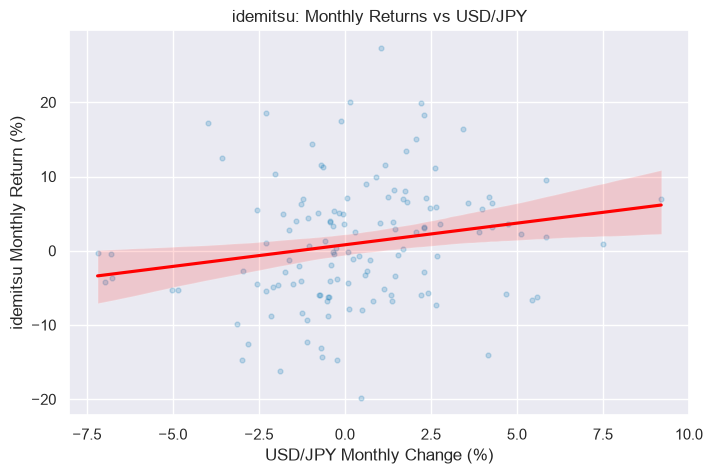

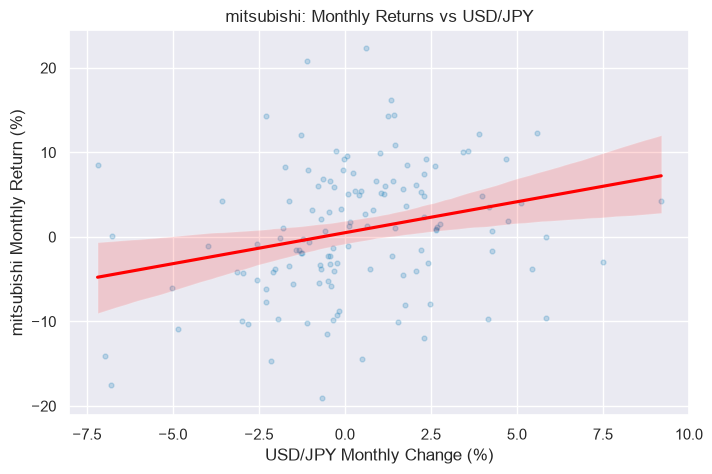

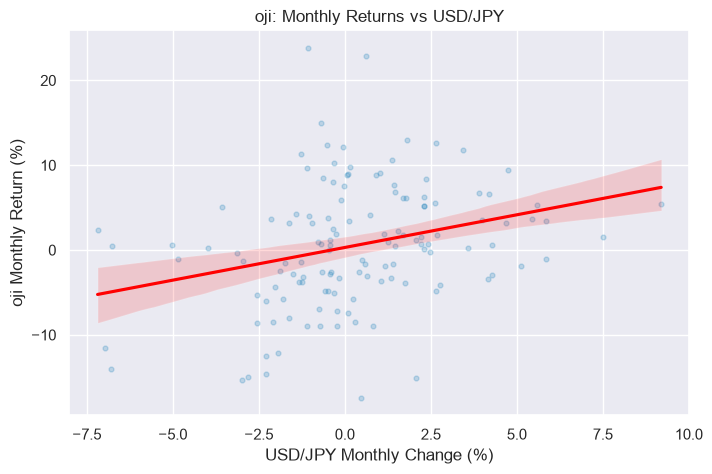

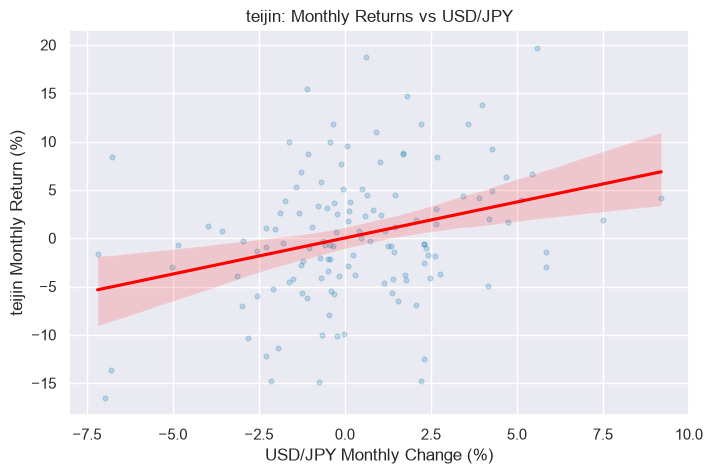

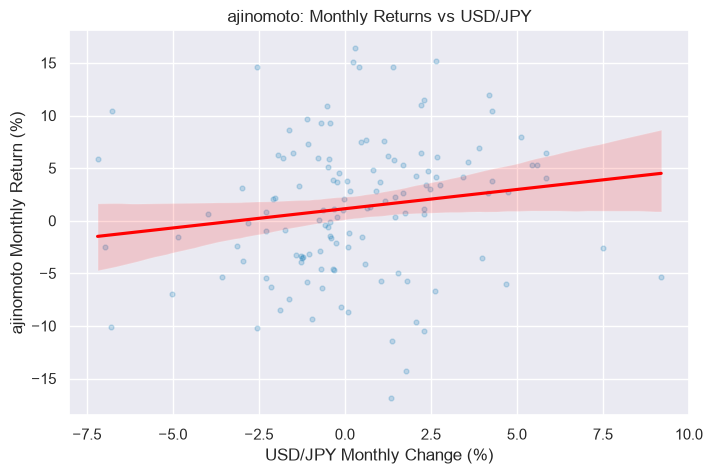

...

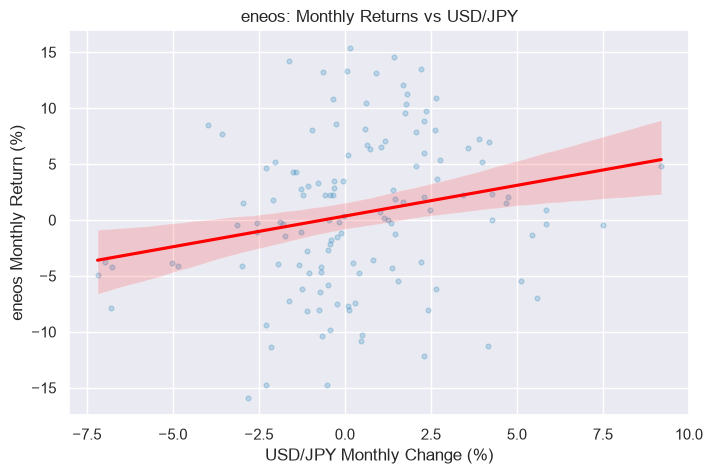

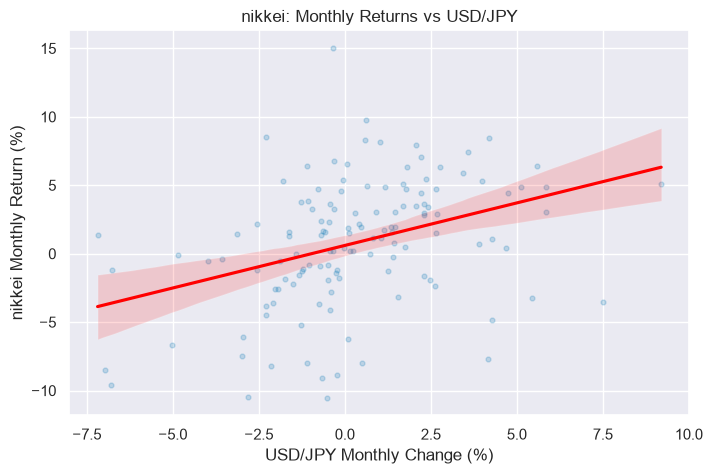

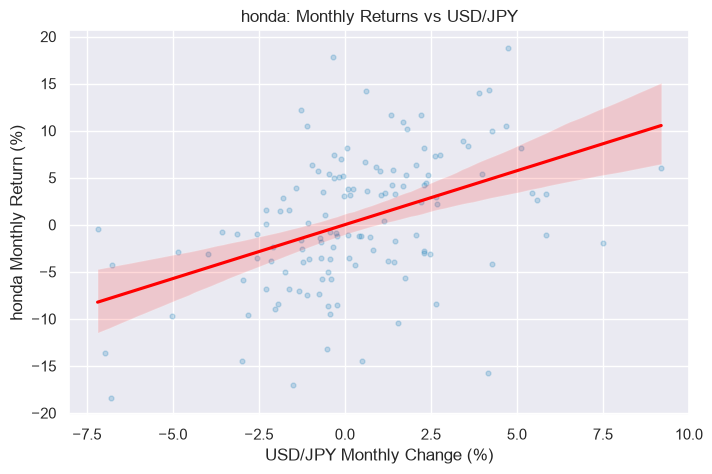

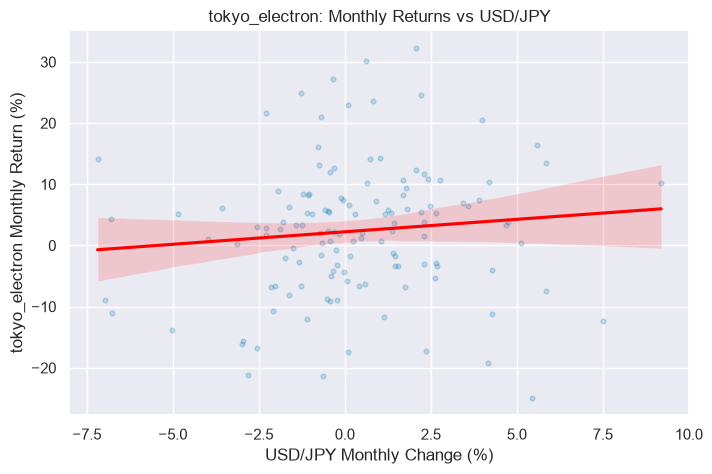

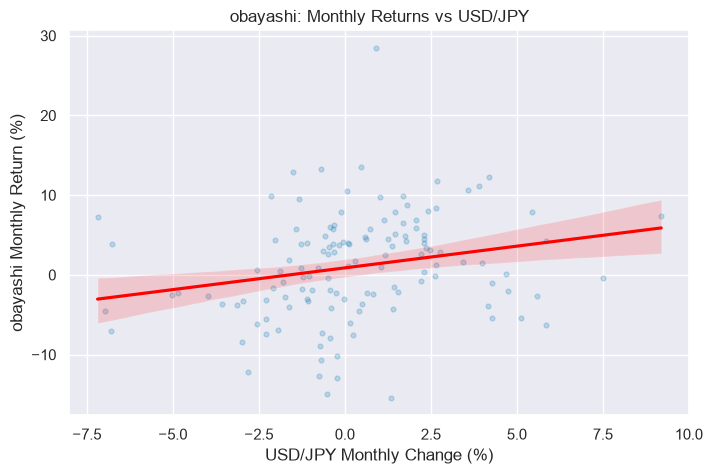

In [10]:
for name in stocks:
#Skipping Yen_USD in graphing
    if name == "yen_usd":
        continue

    plt.figure(figsize = (8, 5))

    sns.regplot(
        data = monthly_returns,
        x = "yen_usd",
        y = name,
        scatter_kws = {"alpha": 0.2, "s": 12},
        line_kws = {"color": "red"}
    )

    plt.title(f"{name}: Monthly Returns vs USD/JPY")
    plt.xlabel("USD/JPY Monthly Change (%)")
    plt.ylabel(f"{name} Monthly Return (%)")
    plt.show()

### Monthly Observations

When looking at monthly returns the error is a lot larger, however, we can see that many of the stocks are now either closer to 0 correlation, with a few firms like Toyota and Honda reflecting potentially high correlations. The nikkei index is also showing a positive correlation as well.

### Looking at Correlation Heatmaps

#### Cumulative change vs USD/Yen

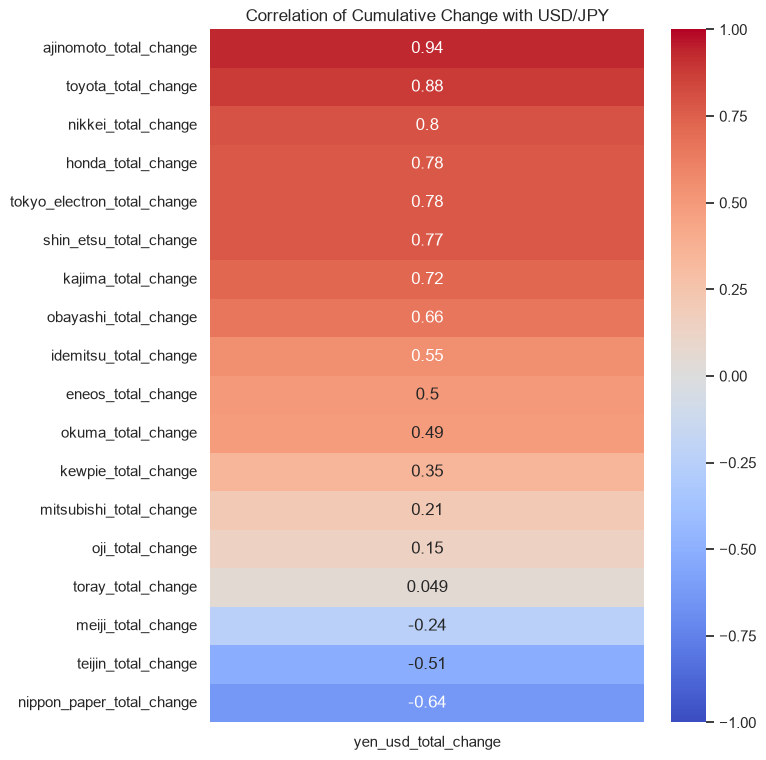

In [11]:
# Selecting the total change columns
total_cols = [f"{name}_total_change" for name in stocks]
if "yen_usd_total_change" not in total_cols:  
    total_cols.append("yen_usd_total_change")

# Calculate correlations
correlations_total = stock_prices[total_cols].corr()

# Select only correlations with USD/JPY
yen_correlations_total = correlations_total[["yen_usd_total_change"]].drop(
    index = "yen_usd_total_change"
)

# Plot
plt.figure(figsize=(7, 9))

sns.heatmap(
    yen_correlations_total.sort_values(
        by = "yen_usd_total_change",
        ascending = False),
    annot = True,
    cmap = "coolwarm",
    center = 0,
    vmin = -1,
    vmax = 1
)

plt.title("Correlation of Cumulative Change with USD/JPY")
plt.show()

### Cumulative Correlation Observations
This column of data is really interesting. The firm with the highest correlation is ajinomoto with a coefficient of .94. Looking at the cumulative graph we can also see that it appears to move in tandum with yen/usd movements. This might have to do with ajinomoto being a major producer of semiconductors, which are especially connected to the U.S. economy. It is also important to consider that since the time frame is so large, well performing stocks will naturally flag a high correlation with the yen/usd movements, which have also been trending upwards in the 2014 - 2024 window. Other firms that reflect large correlations are Toyota, Honda, and Tokyo electron. It appears that the highest correlation firms are within similar sectors, typically transportation or manufacturing. The lower ends like nippon paper and teijin, which are members of the paper and textile sectors. It is also important to notice that the correlations presented here are rather high compared to the findings we will make below

### Monthly Correlation Heatmap

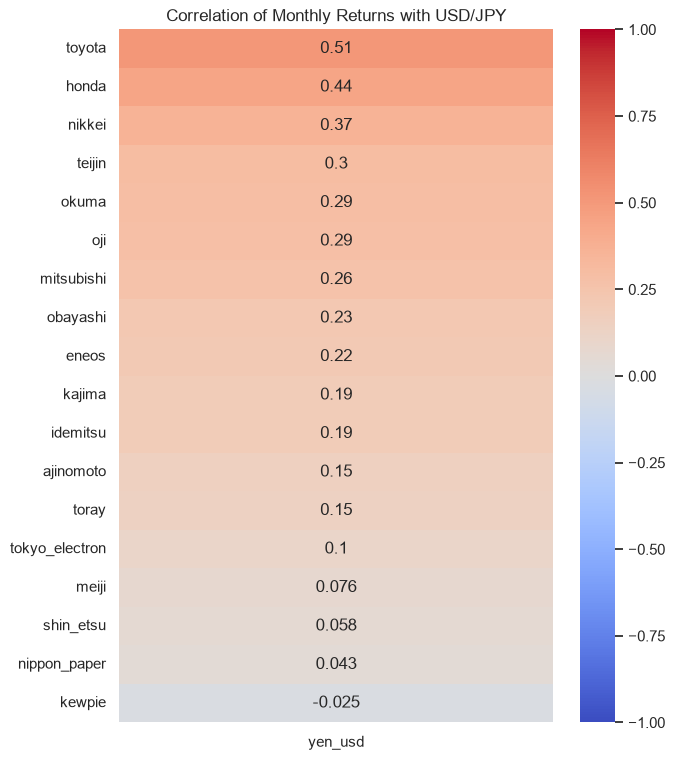

In [12]:
# Calculate correlations
correlations_month = monthly_returns[stock_names].corr()

# Select only correlations with USD/JPY
yen_correlations_month = correlations_month[["yen_usd"]].drop(
    index = "yen_usd"
)

# Plot
plt.figure(figsize=(7, 9))

sns.heatmap(
    yen_correlations_month.sort_values(
        by="yen_usd",
        ascending=False),
    annot = True,
    cmap = "coolwarm",
    center = 0,
    vmin =- 1,
    vmax=  1
)

plt.title("Correlation of Monthly Returns with USD/JPY")
plt.show()

### Monthly Return Observations

When looking at monthly changes are data changes a lot. We now have significanly more weaker correlations. Meiji, Nippon Paper Shin-etsu, and kewpie all have near 0 correlations. Signialling that these stocks might have little to no relation to Yen/USD movements.

We do also see some stocks with much higher coefficients in this window. Toyota's coefficient is now .51, indicading a moderate relationship between USD/Yen movements. Honda also experiences a large increase to .44.

Some other notable changes are mitsubishi, teijin, nikkei, oji, eneos, and okuma; which increased to the ranges of .37 to 22.

### Daily Correlation Heatmap

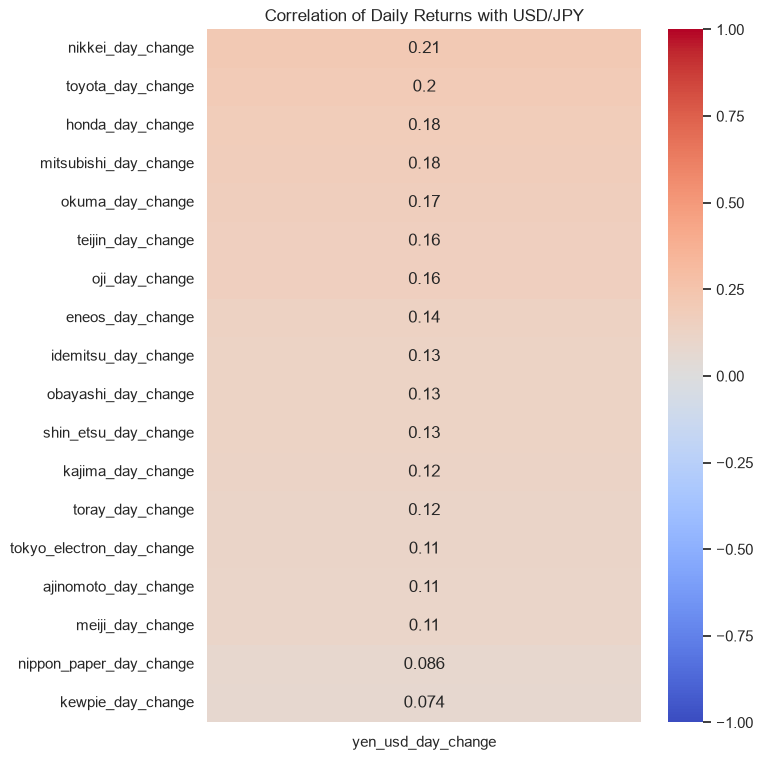

In [13]:
# Select daily change columns
daily_cols = [f"{name}_day_change" for name in stocks]

# Calculate correlations
correlations_day = stock_prices[daily_cols].corr()

# Select only correlations with USD/JPY
yen_correlations_day = correlations_day[["yen_usd_day_change"]].drop(
    index="yen_usd_day_change"
)

# Plot
plt.figure(figsize = (7, 9))

sns.heatmap(
    yen_correlations_day.sort_values(
        by = "yen_usd_day_change",
        ascending = False),
    annot = True,
    cmap = "coolwarm",
    center = 0,
    vmin = -1,
    vmax = 1
)

plt.title("Correlation of Daily Returns with USD/JPY")
plt.show()

### Daily Correlation Observations
looking at daily return correlations we can see all the stocks have very low correlation coefficients to yen_usd movements. The lowest being nippon papper with .093, basically 0 correlation. The highest correlations we can see are the Nikkei with .23 and Toyota with .21. Slightly stronger correlations but still considerably weak. The rest of the stocks show coefficients .12 to .18 ranges.

### Correlation Observations Across all time frames

Interestingly enough if we look at the cumulative correlations, the firm that had the highest ratio, ajinomoto, shifted greatly as we shrink the observation window. However, the transportation industries remained in the top 5 highest correlations throughout all 3 heatmaps. We can also see the the Nikkei remained in the top 5 as well, with it holding the top daily correlation with a coefficient of .21. 

### Creating a 90day rolling graph to see how the correlation changess over 90 day periods

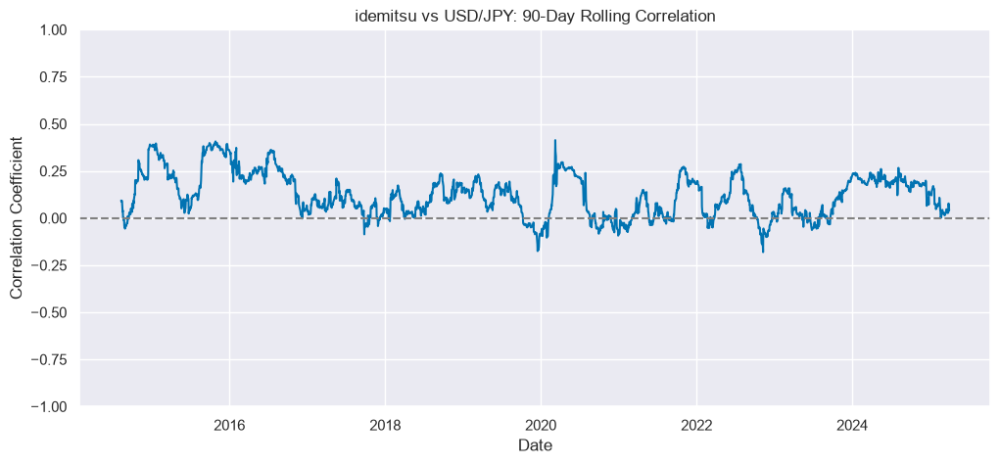

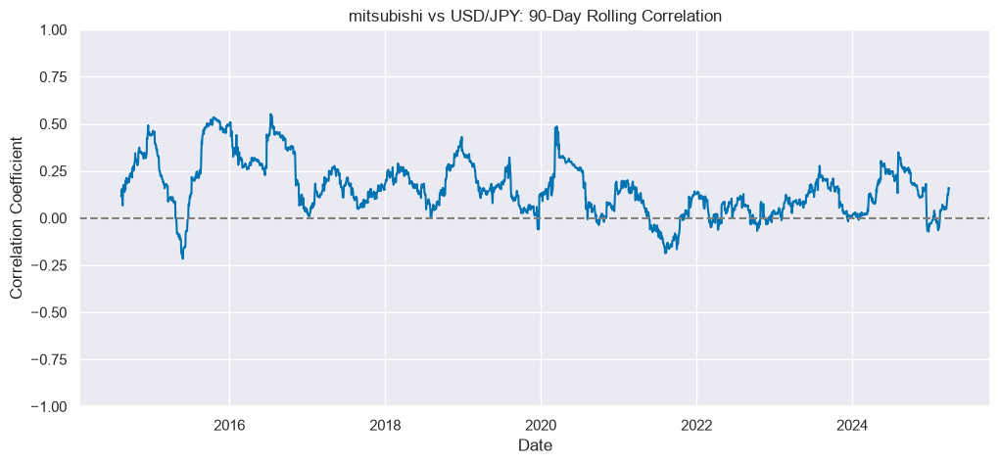

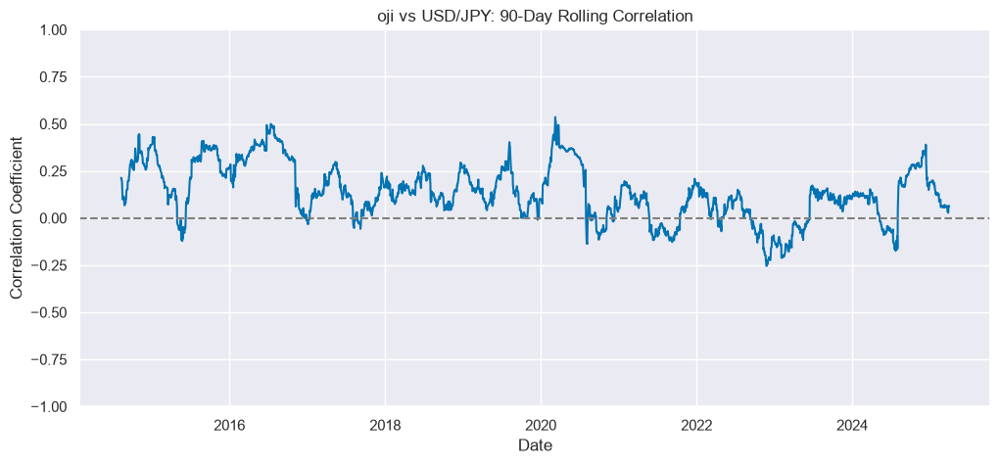

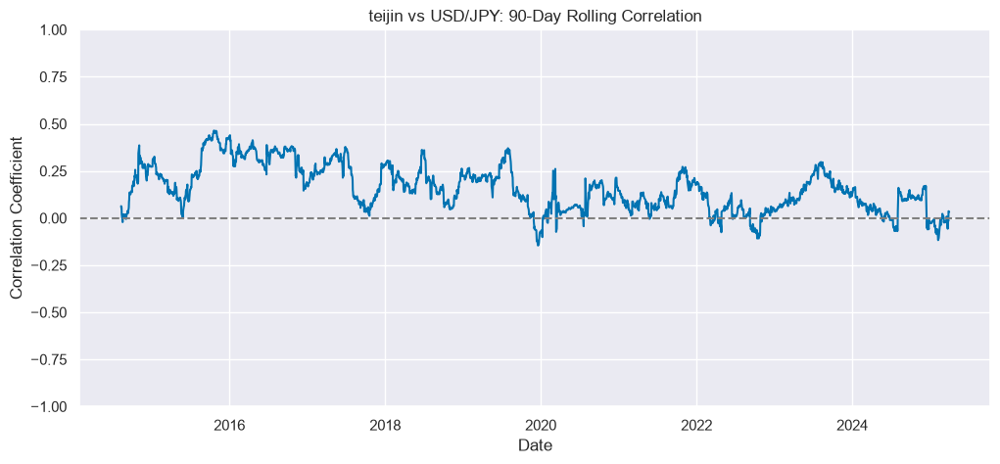

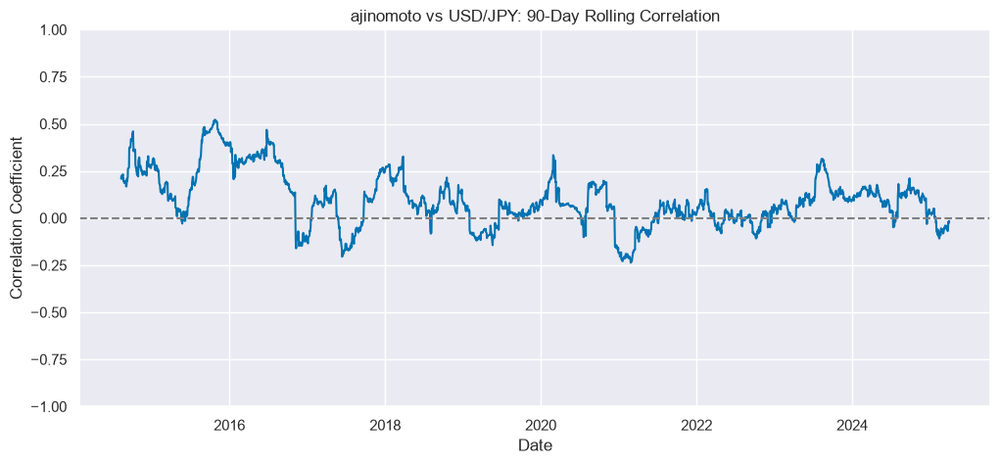

...

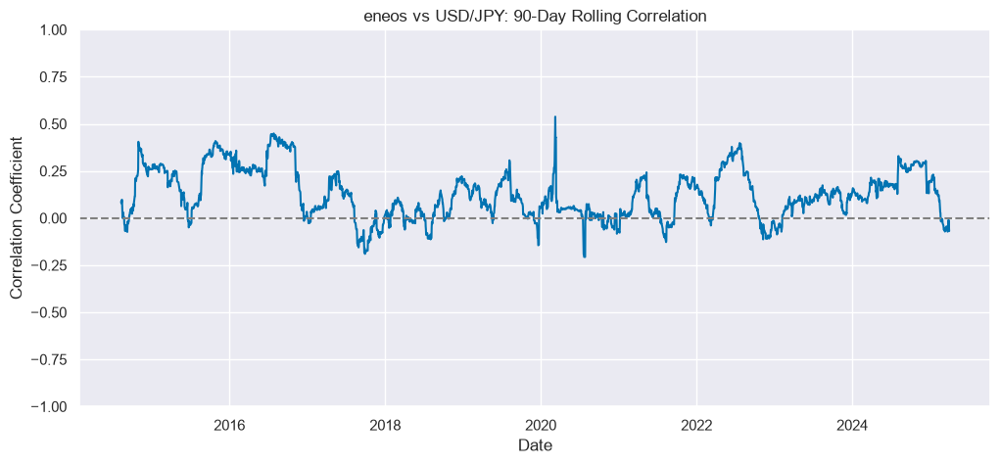

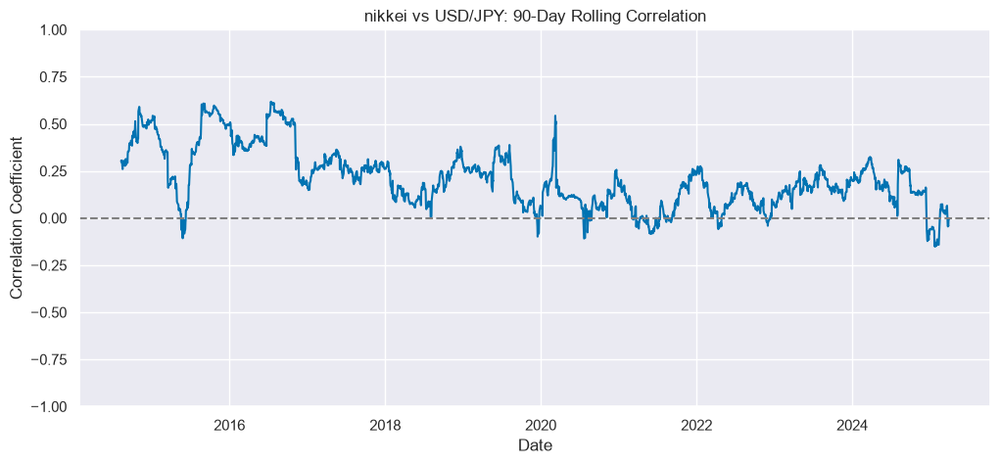

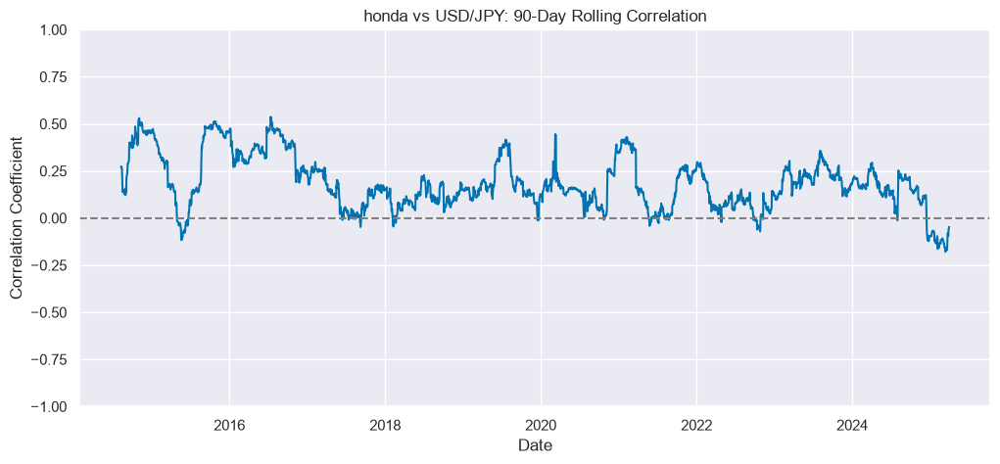

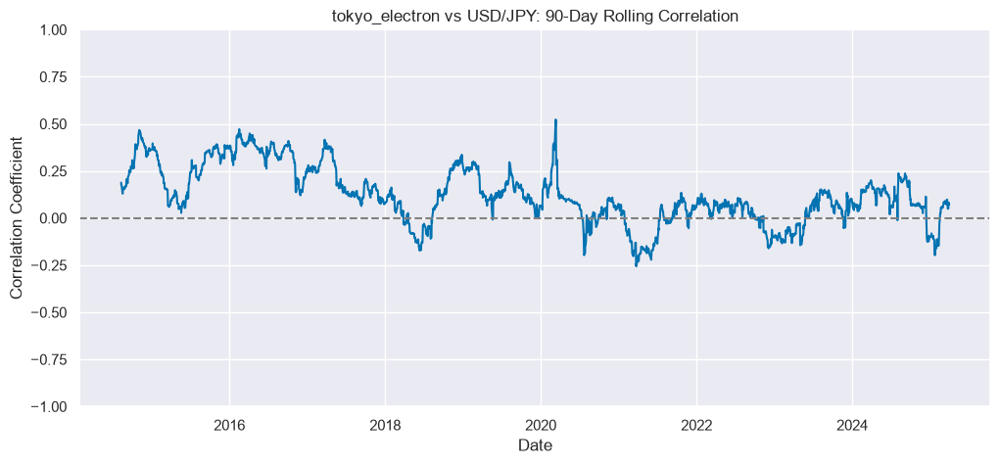

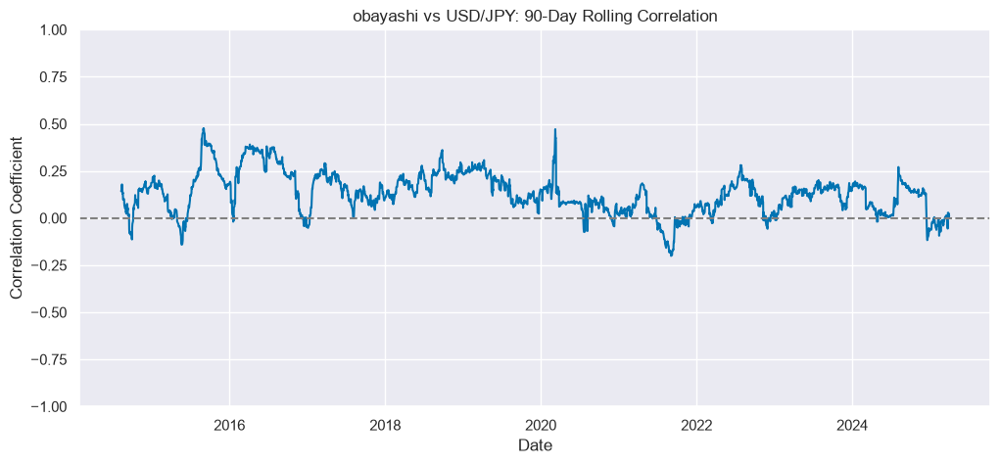

In [14]:
for name in stocks:
    if name == "yen_usd":
        continue

    stock_prices[f"{name}_rolling_corr"] = (
        stock_prices[f"{name}_day_change"]
        .rolling(window = 90)
        .corr(stock_prices["yen_usd_day_change"])
    )
    
    
    plt.figure(figsize = (12, 5))
    
    sns.lineplot(
        data = stock_prices,
        x = "Date",
        y = f"{name}_rolling_corr"
    )

    plt.axhline(0, color = "gray", linestyle = "--")
    
    plt.title(f"{name} vs USD/JPY: 90-Day Rolling Correlation")
    plt.ylabel("Correlation Coefficient")
    plt.ylim(-1, 1)
    plt.show()

### 90 Day rolling observations

Looking at the 90 day rolling correlation we see that the correlations vary widely over time. For some firms there may be a moderate positive correlation for a few years to no correlation to to moderate negative correlation. This means that the correlation between yen and usd is rather fluid, likely due to many aditional factor outside of USD/yen impacting stock returns. 

# Now lets incorporate the Government reported foreign export data into our analysis

In [15]:
# Load the export data
industry_exports = pd.read_csv("Export Ratios.csv")

# Keep only industry-level data and necessary columns
industry_data = industry_exports.loc[
    industry_exports["level"] == "industry",
    ["fiscal_year", "industry_en", "export_ratio_pct"]
].copy()

# Standardize the industry column name
industry_data.rename(
    columns={"industry_en": "industry"},
    inplace=True
)

#Labeling stocks based on their industry"
stock_industries = {
    "idemitsu": "Petroleum & Coal",
    "mitsubishi": "Chemicals",
    "oji": "Wood, Paper & Pulp",
    "teijin": "Textiles",
    "ajinomoto": "Food Products",
    "kajima": "Construction",
    "okuma": "Production Machinery",
    "kewpie": "Food Products",
    "toyota": "Transport Equipment",
    "toray": "Textiles",
    "meiji": "Food Products",
    "nippon_paper": "Wood, Paper & Pulp",
    "shin_etsu": "Chemicals",
    "eneos": "Petroleum & Coal",
    "honda": "Transport Equipment",
    "tokyo_electron": "Production Machinery",
    "obayashi": "Construction"
}

industry_list = ["Transport Equipment",
                 "Textiles",
                 "Chemicals",
                 "Production Machinery",
                 "Food Products",
                 "Wood, Paper & Pulp",
                 "Petroleum & Coal",
                 "Construction"
                ]
                 

avg_exports = (
    industry_data.groupby("industry")["export_ratio_pct"].mean()
)

display(avg_exports.sort_values(ascending=False))

industry
Business-Use Machinery             49.327273
Production Machinery               48.481818
Info & Communication Equipment     45.945455
Transport Equipment                45.454545
Non-Ferrous Metals                 31.300000
General-Purpose Machinery          30.809091
Electrical Machinery               29.163636
Other Manufacturing                27.454545
Iron & Steel                       26.381818
Chemicals                          25.763636
Ceramics, Stone & Clay             25.454545
Transportation (services)          21.754545
Wholesale                          16.990909
Services                           16.709091
Agriculture, Forestry & Fishery    14.527273
Textiles                           11.000000
Metal Products                     10.709091
Petroleum & Coal                   10.554545
Wood, Paper & Pulp                  8.009091
Construction                        5.718182
Mining                              4.163636
Information & Communications        3.109091
F

### Average Export Data
#### For our data have 
#### prod. machinery | 49%
#### Transport | 45.45%
#### Chemicals | 25.79%
#### Textiles | 11%
#### Petroleum | 10.55%
#### Wood, Paper, Pulp | 8%
#### Food | 2.24%

\
\
**LIMITATION**
\
A potential limitation of this data, however, is that it's a rather crude generalization. Most of the stocks we are looking at may not neatly fall into these categories. A much more accurate strategie would be to look at each individual stocks reports on export sales, but those aren't widely available. 

### Now lets see how these numbers move over time in relation to Yen/USD

In [16]:
# Making a yearly yen data fram
yearly_yen = stock_prices[["Date", "yen_usd"]].copy()

# Adjusting yearly yen to the Fiscal Year range of our data (April to March)
yearly_yen["fiscal_year"] = (
    yearly_yen["Date"].dt.year
    - (yearly_yen["Date"].dt.month < 4)
)

# Getting the first and last exchange rate of a fiscal year
yearly_yen = yearly_yen.groupby("fiscal_year").agg(
    yen_start=("yen_usd", "first"),
    yen_end=("yen_usd", "last")
).reset_index()

# Creating the yearly percent change
yearly_yen["yen_change_pct"] = (
    (yearly_yen["yen_end"] / yearly_yen["yen_start"] - 1) * 100
)

display(yearly_yen)

,fiscal_year,yen_start,yen_end,yen_change_pct
0,2014,103.66,120.13,15.888482
1,2015,119.75,112.58,-5.987474
2,2016,111.72,111.39,-0.295381
3,2017,110.90,106.24,-4.201984
4,2018,105.91,110.85,4.664338
5,2019,111.35,107.53,-3.430624
6,2020,107.17,110.72,3.312494
7,2021,110.60,121.70,10.036166
8,2022,122.53,132.76,8.348976
9,2023,132.42,151.33,14.280320


### Adjusted fiscal year yen movement observations

Looking at the fiscal year data, during out 10 year window we see yen depreciating conderably with numerous years at over 10% drops in conversion values. In 2014 the rate goes from 103 yen per dollar to 120 yen per dollar.

We can also see that the data goes from 120 down to 107 from 2014 to 2019. The yen/usd rate after those years starts to depreciate considerably hoing to a year end of 149.97 yen at the end of the 2024 fiscal year.

### Combining yen data with industry export ratios over fiscal year

In [17]:
# Collecting industry data of only the industries in our da
industry_data = industry_exports[
    industry_exports["level"] == "industry"
][["fiscal_year", "industry_en", "export_ratio_pct"]].copy()


industry_data = industry_data.rename(
    columns={"industry_en": "industry"}
)

# Merge industry export data with annual USD/JPY changes
export_yen = industry_data.merge(
    yearly_yen[["fiscal_year", "yen_change_pct"]],
    on="fiscal_year",
    how="inner",
    validate="many_to_one"
)

display(export_yen)

,fiscal_year,industry,export_ratio_pct,yen_change_pct
0,2014,Food Products,1.3,15.888482
1,2014,Textiles,10.8,15.888482
2,2014,"Wood, Paper & Pulp",8.1,15.888482
3,2014,Chemicals,22.8,15.888482
4,2014,Petroleum & Coal,8.0,15.888482
...,...,...,...,...
270,2024,Transportation (services),12.0,-1.107814
271,2024,Wholesale,13.9,-1.107814
272,2024,Retail,2.1,-1.107814
273,2024,Services,14.5,-1.107814


### Graphing Yen Movements per year over the Export ratio changes per year

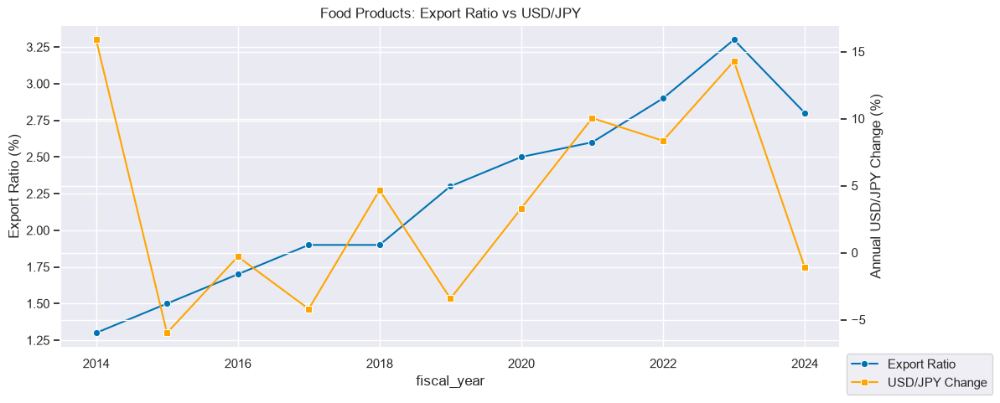

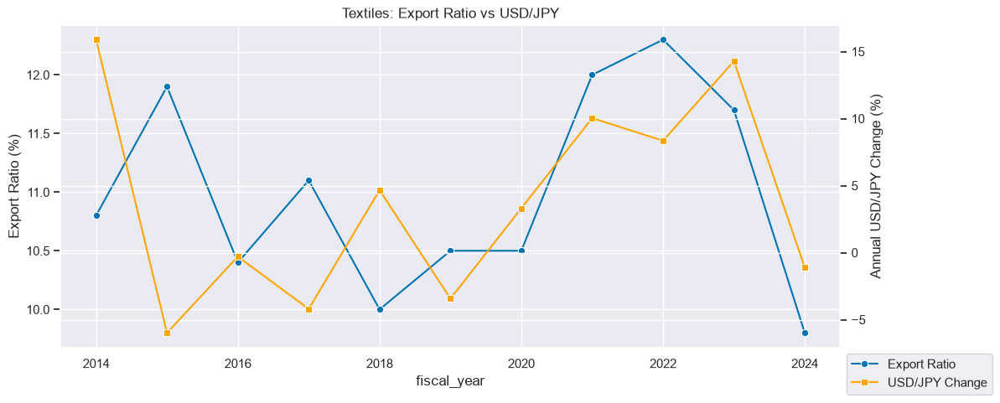

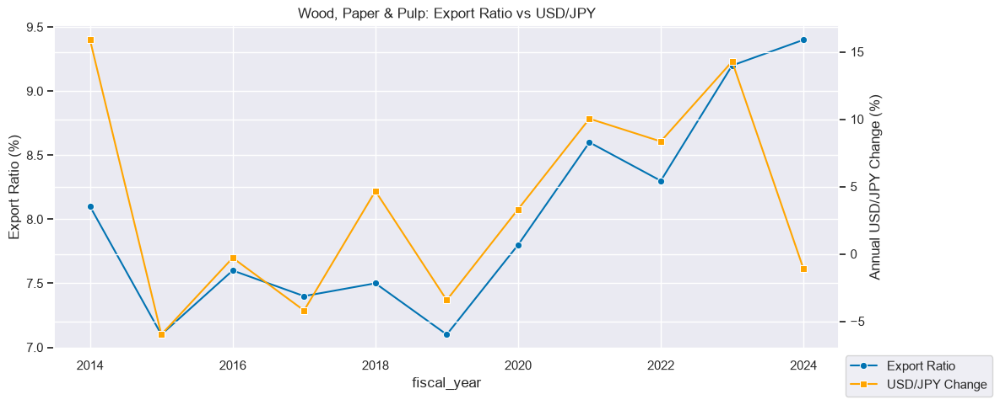

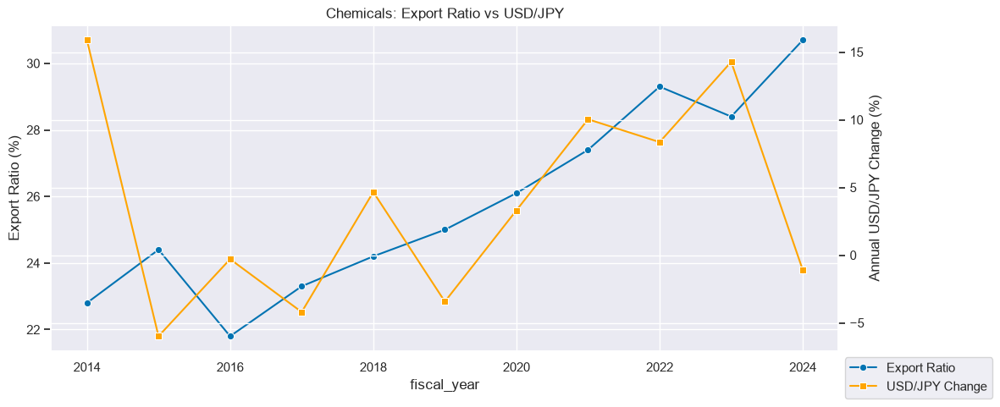

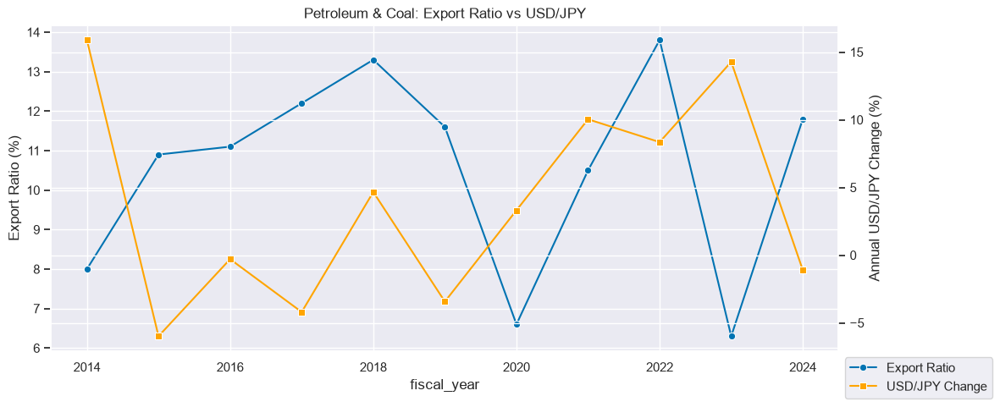

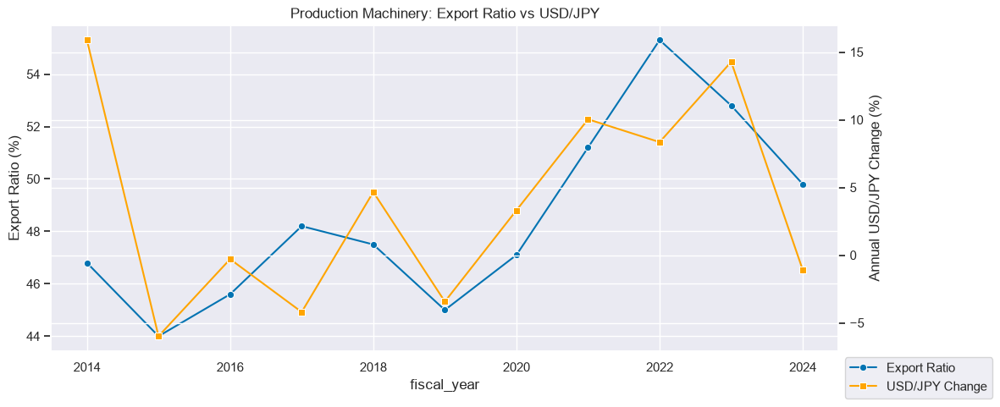

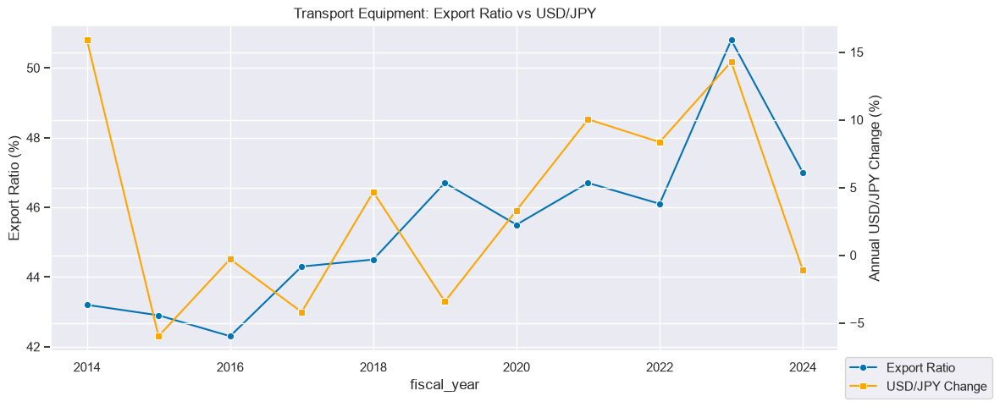

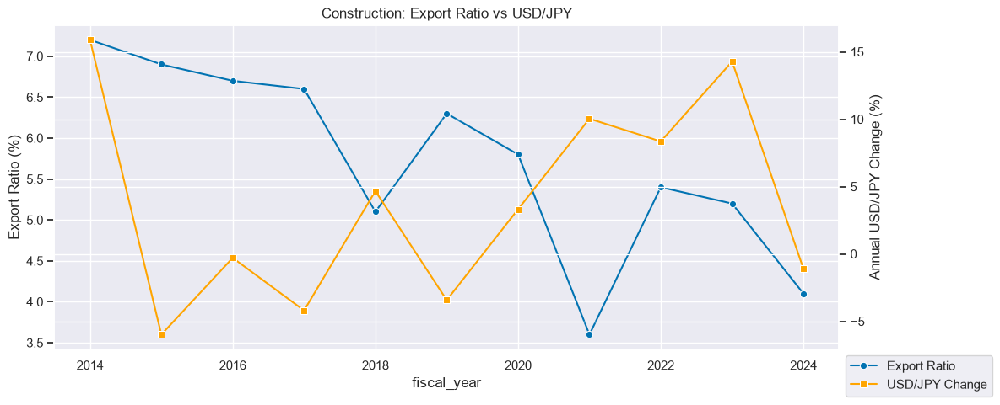

In [18]:
for industry in export_yen["industry"].unique():

    if industry in stock_industries.values():

        # Filter for the current industry
        current_industry = export_yen[
            export_yen["industry"] == industry
        ]

        # Create a figure and first axis
        fig, ax1 = plt.subplots(figsize=(12, 5))

        # Plot export ratios
        sns.lineplot(
            data = current_industry,
            x = "fiscal_year",
            y = "export_ratio_pct",
            marker = "o",
            label = "Export Ratio",
            ax = ax1
        )

        ax1.set_ylabel("Export Ratio (%)")

        # Create a second y-axis
        ax2 = ax1.twinx()

        # Plot annual USD/JPY movement
        sns.lineplot(
            data = current_industry,
            x = "fiscal_year",
            y = "yen_change_pct",
            marker = "s",
            color = "orange",
            label = "USD/JPY Change",
            ax = ax2
        )

        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        
        ax1.legend(
            lines1 + lines2,
            labels1 + labels2,
        )
        
        sns.move_legend(ax1, "upper left", bbox_to_anchor=(1, 0))
        
        # Remove the second legend
        ax2.get_legend().remove()
        
        ax2.set_ylabel("Annual USD/JPY Change (%)")
        plt.title(f"{industry}: Export Ratio vs USD/JPY")
        plt.show()

## Export vs Yen Yearly Observations
When looking at the changes in exports we can see some interesting trends

Many of the graphs again tend to either follow the or mirrior the trends of USD/Yen. For example looking at transportation equipment we run into various years, like 2016- 2020 where export ratios would drop when yen/usd exchange rates would increase (Positive Change in USD/JPY means Yen is getting weaker). This was a bit surprising because my gut reaction was that weaker yen leads to more exports, but for this industry a weakening yen years would have cooling export ratios.

Looking at Food products we see it is steadily increasing over the decade from 1.25% to a max of 3.25%. The export ratios dont appear to be shifting too much in response to USD/JPY movements, the biggest reaction appears to be in 2018 and 2019 where a weakening yen in 2018 saw a flat export ratio and the following year of strenghtening yen saw a increase in export ration of around .6%.

Interestingly enough, it looks like paper and pulp shifter alongside yen/usd movements the most

### Correlation heatmap of industry export ratio changes

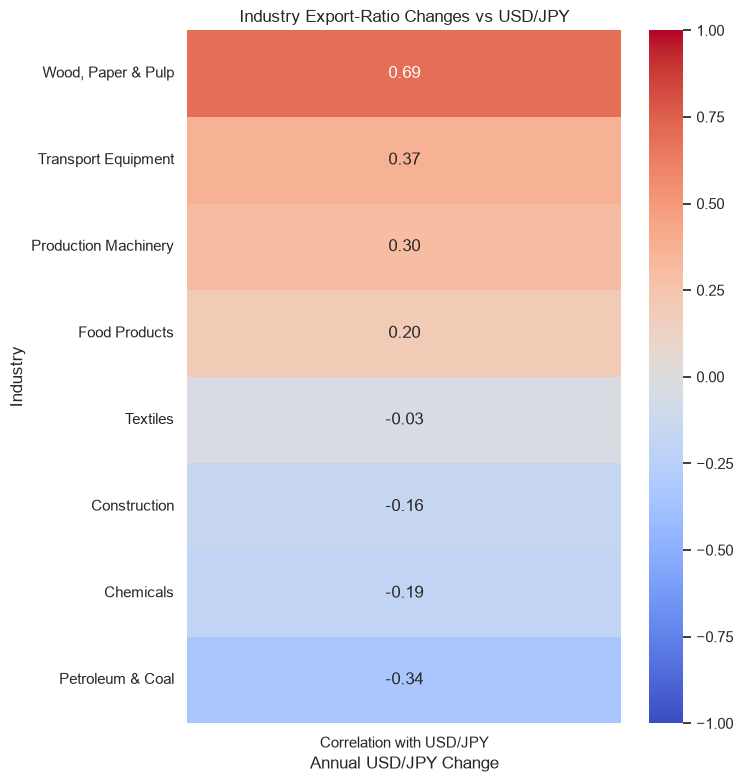

In [19]:
# Sort by industry and fiscal year
export_yen = export_yen.sort_values(
    ["industry", "fiscal_year"]
)

# Calculate annual changes in export ratios
export_yen["export_ratio_change"] = (
    export_yen.groupby("industry")["export_ratio_pct"]
    .diff()
)

#Removing Industries that are not in our data
export_yen = export_yen[
    export_yen["industry"].isin(stock_industries.values())
].copy()


industry_corr = (
    export_yen.groupby("industry")
    .apply(
        lambda df: df["yen_change_pct"].corr(
            df["export_ratio_change"]
        )
    )
)

industry_corr = industry_corr.to_frame(
    name = "Correlation with USD/JPY"
)

plt.figure(figsize=(7, 9))

sns.heatmap(
    industry_corr.sort_values(
        by = "Correlation with USD/JPY",
        ascending = False
    ),
    annot = True,
    cmap = "coolwarm",
    center = 0,
    vmin = -1,
    vmax = 1,
    fmt = ".2f"
)

plt.title("Industry Export-Ratio Changes vs USD/JPY")
plt.xlabel("Annual USD/JPY Change")
plt.ylabel("Industry")
plt.show()

### Correlation Observations of industries

Looking our heat map, a positive number indicated that yen weakening compared to USD correlates with an increase in exports. On the flip side, a negative number indicates that a strengthening yen correlates with an increase in exports.

The industry with the highest positive correlation is Wood, Paper & Pulp with a .69 correlation. This was very interesting considering it has a rather low export percentage. The wood and pulp firms were also some of the worst performing stocks in relation to Yen/USD, so it is a bit surprising to see the correlation coefficient being so high.

### Organizing stock by fiscal year and labeling the type of industry

In [20]:
stock_prices["fiscal_year"] = (
    stock_prices["Date"].dt.year
    - (stock_prices["Date"].dt.month < 4)
)


yearly_correlations = []

for year, df in stock_prices.groupby("fiscal_year"):

    for name in stock_industries:

        stock_col = f"{name}_day_change"

        # Calculate correlation within this fiscal year
        corr = df[stock_col].corr(
            df["yen_usd_day_change"]
        )

        yearly_correlations.append({
            "fiscal_year": year,
            "company": name,
            "industry": stock_industries[name],
            "stock_corr": corr
        })

yearly_corr_df = pd.DataFrame(yearly_correlations)

display(yearly_corr_df.head())


,fiscal_year,company,industry,stock_corr
0,2014,idemitsu,Petroleum & Coal,0.210401
1,2014,mitsubishi,Chemicals,0.197418
2,2014,oji,"Wood, Paper & Pulp",0.192892
3,2014,teijin,Textiles,0.179247
4,2014,ajinomoto,Food Products,0.185059


### Adding export ratio percentages to the Dataframe

In [21]:
# Merging yearly comparison with industry data
yearly_comparison = yearly_corr_df.merge(
    industry_data,
    on = ["fiscal_year", "industry"],
    how = "left",
    validate = "many_to_one"
)

display(yearly_comparison)

,fiscal_year,company,industry,stock_corr,export_ratio_pct
0,2014,idemitsu,Petroleum & Coal,0.210401,8.0
1,2014,mitsubishi,Chemicals,0.197418,22.8
2,2014,oji,"Wood, Paper & Pulp",0.192892,8.1
3,2014,teijin,Textiles,0.179247,10.8
4,2014,ajinomoto,Food Products,0.185059,1.3
...,...,...,...,...,...
182,2024,shin_etsu,Chemicals,-0.005241,30.7
183,2024,eneos,Petroleum & Coal,0.185073,11.8
184,2024,honda,Transport Equipment,0.041815,47.0
185,2024,tokyo_electron,Production Machinery,0.069170,49.8


### Correlations grouped by industry

In [23]:
#Creating a new df to look at correlations grouped by industry
industry_year_corr = (
    yearly_comparison.groupby(["fiscal_year", "industry"])
    .agg(
        mean_stock_corr=("stock_corr", "mean"),
        export_ratio_pct=("export_ratio_pct", "first")
    )
    .reset_index()
)

industry_year_corr

,fiscal_year,industry,mean_stock_corr,export_ratio_pct
0,2014,Chemicals,0.251147,22.8
1,2014,Construction,0.054296,7.2
2,2014,Food Products,0.109959,1.3
3,2014,Petroleum & Coal,0.206589,8.0
4,2014,Production Machinery,0.245041,46.8
...,...,...,...,...
83,2024,Petroleum & Coal,0.163948,11.8
84,2024,Production Machinery,0.090405,49.8
85,2024,Textiles,0.023082,9.8
86,2024,Transport Equipment,0.072912,47.0


### Graphing Industry Export ratio compared to Average stock correlation

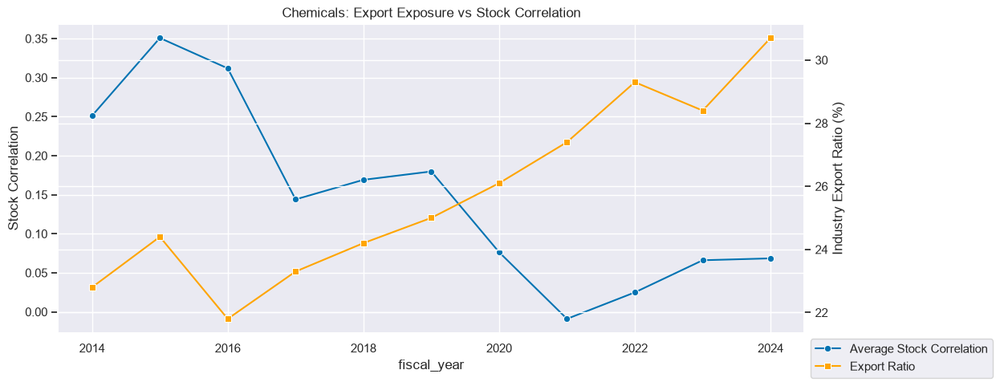

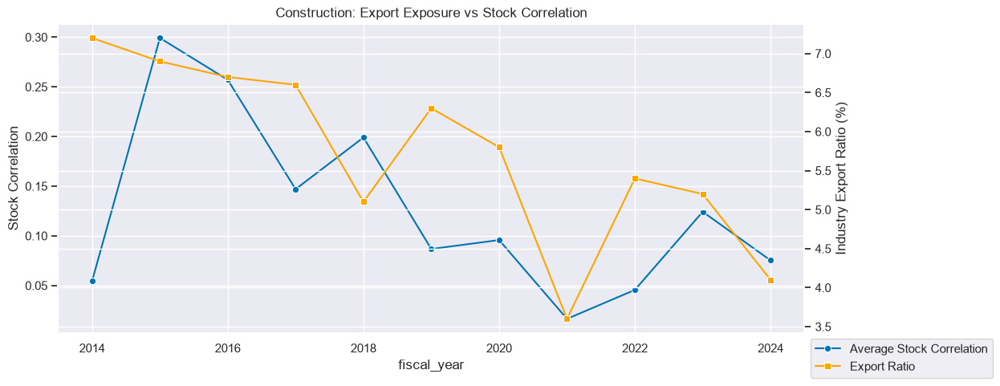

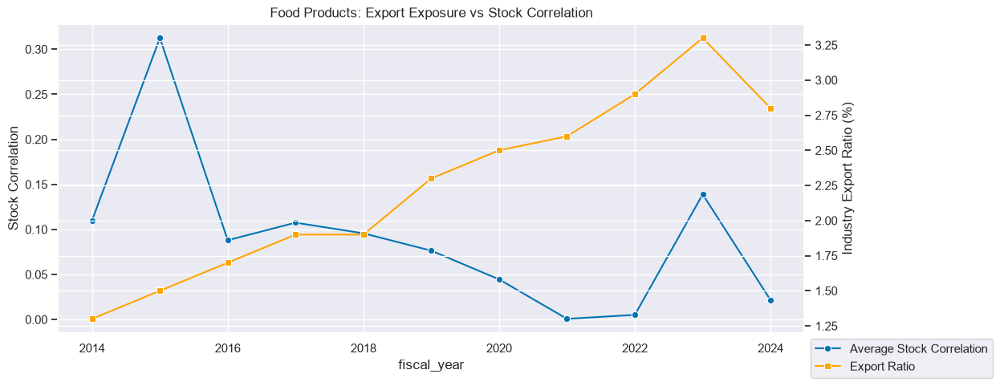

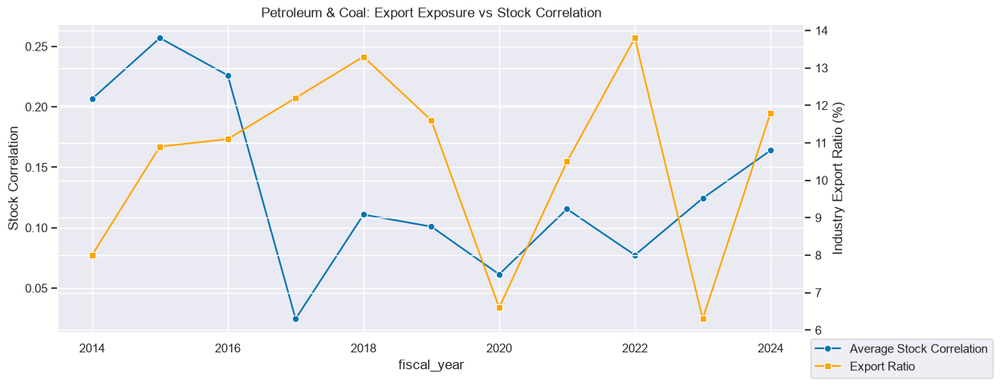

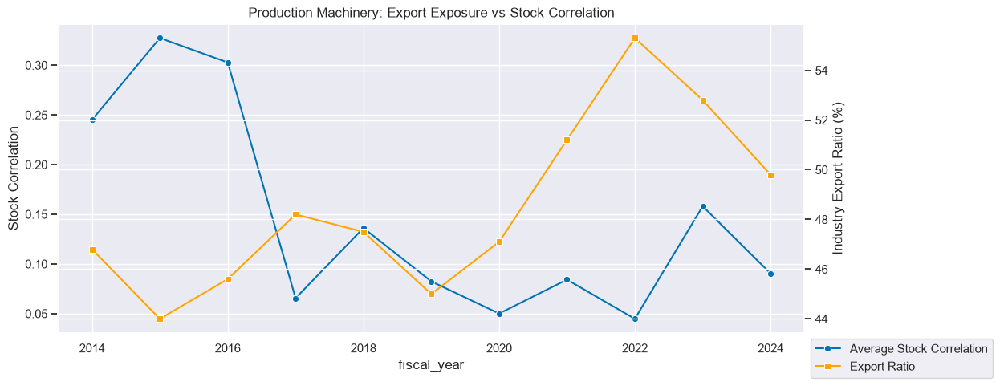

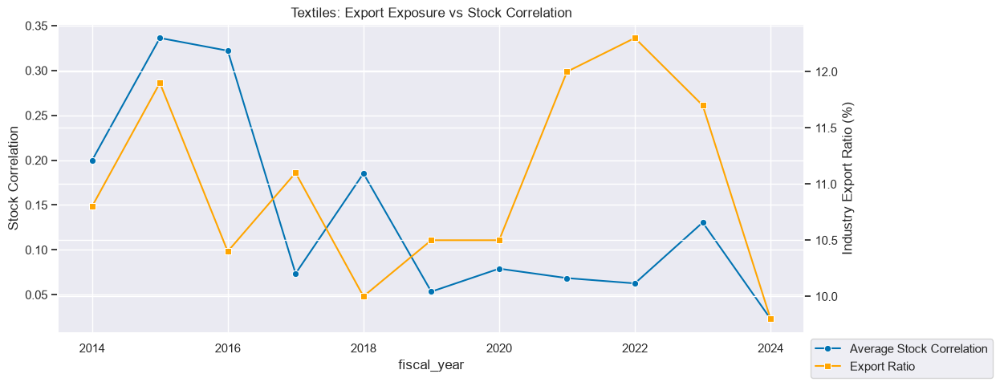

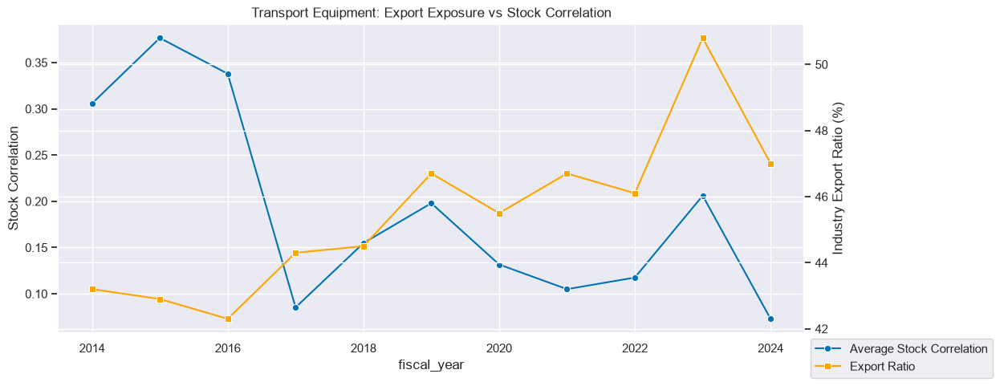

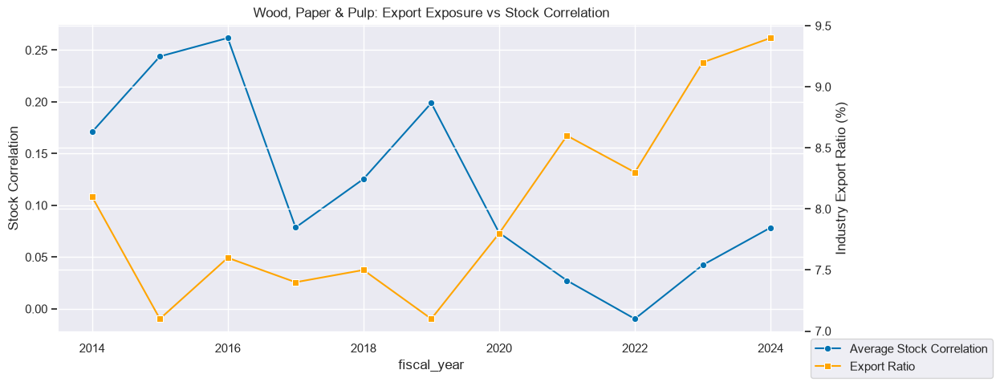

In [26]:
# iterating over unique industries
for industry in industry_year_corr["industry"].unique():
    
# Selecting the correlation coefficient
    corr = industry_year_corr[
        industry_year_corr["industry"] == industry
    ]

# Plotting the correlation for the stock
    fig, ax1 = plt.subplots(figsize=(12, 5))
    
    sns.lineplot(
        data= corr,
        x = "fiscal_year",
        y = "mean_stock_corr",
        marker = "o",
        ax = ax1,
        label = "Average Stock Correlation"
    )

# Labeling axis and joining the graphs   
    ax1.set_ylabel("Stock Correlation")
    
    ax2 = ax1.twinx()
    
    sns.lineplot(
        data = corr,
        x = "fiscal_year",
        y = "export_ratio_pct",
        marker = "s",
        color = "orange",
        ax = ax2,
        label = "Export Ratio"
    )
    
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
        
    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
    )

# Moving the legend to a less obstructive position
    ax2.get_legend().remove()
    sns.move_legend(ax1, "upper left", bbox_to_anchor=(1, 0))

    
    ax2.set_ylabel("Industry Export Ratio (%)")
    plt.title(f"{industry}: Export Exposure vs Stock Correlation")
    plt.show()

### Industry Average Correlation vs Export Ratio Obsevations

Among these graphs we can notice some interesting trends.

* **Chemicals**
    * Stock correlation drops as export ratio rises, reaching its minimum at 2021 (Probably due to covid?). We saw a max correlation of .35 and a minimum of slighly below 0. This industry experienced a wide variance of correlation movement
* **Construction**
    * Stock correlation seems to decrease with export ratio, going from 7% - 4% and experiencing a correlation decline of .3 to .1
* **Food Producs**
    * Export ratios seemed to not budge much at all in relation to export ratio. The biggest similarity was a peak and drop from 2023 to 2024
* **Pretol & Coal**
    * Export ratios seem to inverse stock correlations. When stock correlation decreased it often followed with an inrease in export ratio.
* **Production Machinery**
    * Export ratios varied widely between 14 and 6% but their relation to mean correlation does not appear to be too strong, we can see some mirrioring and some inverse reactions.
* **Textiles**
    * Export ratios in this graph seemed to move hand in hand with correlation but slightly lagged. Where we can see correlation mimicking the movements of export ratios of prior movements
* **Transport**
    * Export ratios are seen to be steadily increasing over time while average correlation drops from .36 to below .1
* **Wood, Pulp, Paper**
    * Export ratios are increasing over time and we see the correlation following usually in the inverse of this trend

### Scatter plot of Export exposure vs USD/JPY correlation grouped by industry type

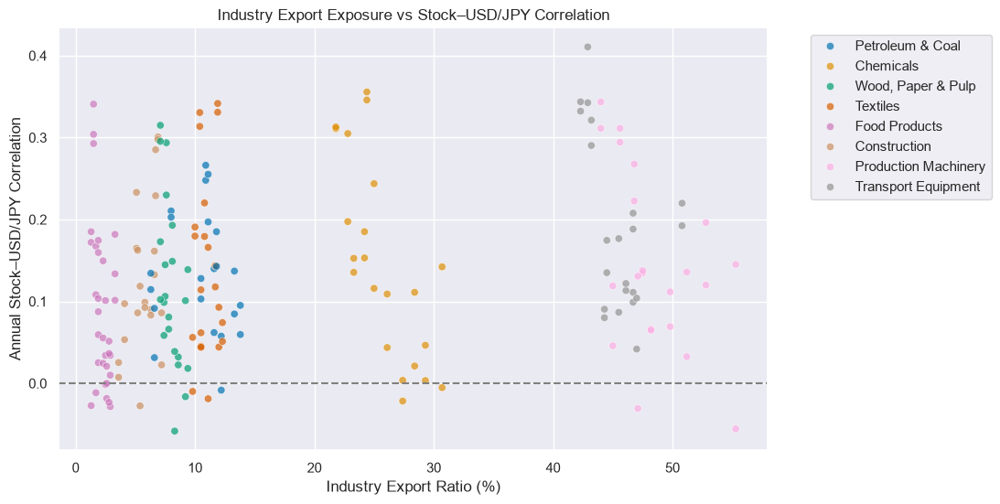

In [25]:
plt.figure(figsize=(10, 6))

sns.set_theme(palette = "colorblind")

sns.scatterplot(
    data = yearly_comparison,
    x = "export_ratio_pct",
    y = "stock_corr",
    hue = "industry",
    alpha = 0.7
)


plt.axhline(0, color="gray", linestyle="--")

plt.title("Industry Export Exposure vs Stock–USD/JPY Correlation")
plt.xlabel("Industry Export Ratio (%)")
plt.ylabel("Annual Stock–USD/JPY Correlation")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

### Indstry Export vs Stock-USD/JPY Correlation observations

Looking at the graph we can clearly see that industries tend to hover around the same export ratios.

Reflecting our ealier data Food, Wood, Petroleum, Textiles, populate the lower export rations while transportation and production machinery populate the higher export ratio percentage.

It appears that there is a slight increase in responsiveness over export ratio. We can also see that there are less data points near zero correlation the higher up in industry export ratio we go up. 

# Findings Summary

In this project we analyzed the relationship between stock movements, USD/Yen movements, and industry export ratios.

We found that many stocks do appear to have some correlation with USD/Yen movements. When observing month to month movements, we observed that transportation related stocks like Toyota and Honda had the highest correlation coefficients of .51 and .44. The lowest in this time interval was Kewpie and Nippon Paper with .045 and -.025. 

When we look at export ratios based on industry, we see that transportation has a high ratio of 45.45%, with the lower end being food and paper products with 2.24% and 8%.

From these two points we can make the observation that businesses with a higher export ratio may correlate more with movements for USD/Yen movements.


When we look at the correlation between industry export ratio changes and USD/yen movements we actually see Wood, Paper, & Pulp with a higher coefficient of .69 than transport equipment with a coefficient of .37. This observation was surprising because the ratio of exports done by that industry is only 8%. 

We then conclude our analysis with an Industry Export Exposure vs Stock-USD/JPY Correlation graph. From this graph we can observe that industry does appear to have a small positive association on annual stock correlation. Industries with a higher export ratio tended to chart higher in correlation coefficient compared to lower ratios.    

## Business Suggestion
Since we observed higher export ratio industries haveing a higher association with yen movements, I would recommend that businesses look at thier own export ratios to decide how to react to exchange rate changes

Firms with high export ratios could benefit to monitoring yen/USD movements regulary and adjusting business strategies based on the strength or weakness of the Yen

Firms with low export ratios may be less directly associated with yen/USD movements, our findings showed even low export firms had some association with yen/USD movement. Therefore, I would suggest that firms in this bracket monitor yen/USD movements if their inputs are sourced primarily from abroad.

### Limitations
* Some of the data sets were missing dates, forcing other data sets to drop those missing dates as well.
* Daily correlation may be subject to time lags, in a future analysis it may be interesting to see how introducing a one day or two day lag impacts the data
* Covid 19 pandemic is within our date ranges. We can see ratios, averages, and returns dropping significantly in the 2020 - 2022 period that may influence our analysis
* Many of the stocks in this data set dont perfectly fit into one specific industry, Ajinomoto and Meiji for example, are very diverse companies that produce food and a wide variety of other goods. It would have been more insightful to use company reported export ratios but that data isn't as widely availble as the industry wide ratios provided by the Japanese government
* Large Scope | This analysis attempts to go over numerous variables at once on a surface level. It is likely worthwhile to narrow the scope and focus purely on yen/usd movements or a smaller set of stocks, then widen the scope later in a seprate analysis

### Data sources 
* Stock CSV data collected from : https://www.wsj.com/market-data
* Industry export ratios collected from : https://www.e-stat.go.jp/stat-search/files?page=1&toukei=00550120&tstat=000001011012


### References
* General Firm and product info (Profile tabs for each stock): https://www.wsj.com/market-data
* Ajinomoto proucts (semiconductors): https://www.ajinomoto.com/innovation/our_innovation/buildupfilm
* Meiji product (Food / Pharmasuticals) : https://www.meiji.com/global/food/